# 第V部：Euler方程式の時間積分

**問い：同じ空間離散化を、前進Euler・SSP-RK2・SSP-RK3で時間発展させると、誤差・安定性・計算量はどう変わるか。**

Roe・LLF (Rusanov)・HLL・HLLCごとに時間積分だけを切り替えます。時間精度の測定と、衝撃波を含む実用問題の比較は別の実験として扱います。

[I 移流・Burgers](01_advection_burgers.ipynb) · [II Eulerの古典的解法](02_euler_classical.ipynb) · [III 近似リーマンソルバー](03_euler_riemann_solvers.ipynb) · [IV 空間再構築](04_spatial_reconstruction.ipynb) · [V 時間積分](05_time_integration.ipynb)

**この部で最初に理解すること**

第III部では境界流束、第IV部ではその入力となる左右状態を学びました。これらが決まると、**いまのセル平均から、その時間変化率を計算できる**ようになります。まだ次の時刻の値そのものが得られたわけではありません。変化率を用いて有限の時間だけ進める操作が時間積分です。

この部では、同じ空間離散化に対して前進Euler、SSP-RK2、SSP-RK3を比較します。「Euler方程式」は流体の物理方程式、「前進Euler法」は時間積分の方法で、同じEulerという名前でも役割は異なります。

初めて読むときは、半離散系の意味、前進EulerとRKの段階更新、時間誤差の図の順に進んでください。SSPの不等式の証明と複素数を用いた安定性の図は、その後に詳しく確認する箇所です。

## 0. 設定と実行方法

`notebooks/` と `src/` の配置を保ち、設定セルを確認して上から実行します。
数値流束・初期条件・境界条件・厳密解は `euler1d_core.py`、空間と時間を独立に選ぶ計算は `euler1d_mol.py`、実験・描画は `euler1d_experiments.py` を使用します。
図のラベルは英語、解説は日本語です。物理量はすべて無次元です。
動画は標準で有効です。Shu–Osherの高解像度参照計算は設定で有効にします。
設定を変更したらカーネルを再起動し、全セルを実行してください。

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/euler1d_mol.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("リポジトリ一式の notebooks/ と src/ の配置を保ってください。")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
import euler1d_core as core
import euler1d_mol as mol
import euler1d_experiments as ex
from euler1d_study import show_table, shu_reference

ex.CACHE.clear()
TABLES = {}
reference = None
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)
print("MOL checks:", len(mol.run_tests()))

Python: 3.11.18 NumPy: 2.4.6


MOL checks: 8


### 0.1 時間積分・空間離散化の設定

| 設定値 | 内容 | 1ステップの右辺評価数 |
|:--|:--|:--|
| `forward_euler` | 前進Euler、時間1次 | 1 |
| `ssprk2` | 2段階SSP-RK2、時間2次 | 2 |
| `ssprk3` | 3段階SSP-RK3、時間3次 | 3 |

`fluxes` は `Roe`、`LLF`、`HLL`、`HLLC` から選びます。
`reconstruction` は `constant` または `muscl`、`limiter` は `minmod`、`mc`、`unlimited` です。`constant` ではリミッターは使いません。

**2つの実験を区別します。**

| 実験 | 空間設定 | 時間刻み |
|:--|:--|:--|
| 時間収束試験 | `temporal_reconstruction`・`temporal_limiter`、固定格子`temporal_n` | 全方式で同じ $\Delta t=T/N_t$。`temporal_steps`で$N_t$を指定 |
| 接触面・衝撃波・動画 | `reconstruction`・`limiter`、`n_basic` | 共通のCFL規則。各方式で状態が異なるので実際の刻みは同一とは限らない |

時間収束試験の標準は区分一定です。非滑らかな勾配制限の切替を避けて時間次数を確認し、続く「MUSCLでも時間収束を測る」でMUSCLを調べます。
`reference_steps` は同じ半離散系をSSP-RK3で積分する2つの細かいステップ数です。基準は同じ格子・同じ流束・同じ再構築・同じ初期値で計算します。

### 0.2 動画の選択肢

| `movie_problem` | 内容 |
|:--|:--|
| `entropy` | 滑らかなエントロピー波の移流 |
| `contact` | 移動する接触不連続面 |
| `contact_static` | 静止する接触不連続面 |
| `sod` | Sod衝撃波管 |
| `double_rarefaction` | 二重希薄波。負圧などで停止した方式は停止後に描かない |
| `lax` | Lax衝撃波管 |
| `transonic` | 音速をまたぐ希薄波 |

`movie_fluxes` は `("Roe", "LLF", "HLL", "HLLC")` の一部または全部を指定します。各流束に1本の動画を作ります。標準は `("HLLC",)` です。
`movie_field` は `"rho"`（密度）、`"u"`（速度）、`"p"`（圧力）、`"e"`（比内部エネルギー）です。
`movie_frames` は表示フレーム数であり、数値積分のステップ数ではありません。
`shu_osher` はこの動画機能の対象外です。動画を省略する場合は `run_movies=False` にします。

In [2]:
CFG = {
    "run_tvd": True,  # スカラー方程式によるTVDの確認演習
    "gamma": 1.4,
    "fluxes": ("Roe", "LLF", "HLL", "HLLC"),
    "time_integrators": ("forward_euler", "ssprk2", "ssprk3"),
    "reconstruction": "muscl",  # 接触面・衝撃波・動画で固定
    "limiter": "minmod",
    "n_basic": 200,
    "cfl": 0.4,
    "wave_speeds": "einfeldt",
    "roe_entropy": 0.1,
    "temporal_reconstruction": "constant",  # 時間収束試験の空間設定
    "temporal_limiter": "minmod",  # constantでは使用しない
    "temporal_n": 48,
    "temporal_t_end": 0.2,
    "temporal_steps": (40, 80, 160, 320),
    "reference_steps": (1280, 2560),
    "fixed_cfl_limit": 0.9,  # 超過時は停止。固定dtを自動変更しない
    "run_time_convergence": True,
    "run_robustness": True,
    "run_extras": False,
    "run_shu_osher": False,
    "n_shu_osher": 400,
    "n_reference": (1600, 3200),
    "reference_limiter": "mc",
    "run_movies": True,
    "movie_problem": "sod",  # 選択肢は直前の表を参照
    "movie_fluxes": ("HLLC",),
    "movie_field": "rho",
    "movie_frames": 41,
    "export_results": True,
}
ex.validate_config(CFG, "time")
OUTPUT_DIR = ROOT / "five_part_outputs" / "temporal"
print(CFG)

{'run_tvd': True, 'gamma': 1.4, 'fluxes': ('Roe', 'LLF', 'HLL', 'HLLC'), 'time_integrators': ('forward_euler', 'ssprk2', 'ssprk3'), 'reconstruction': 'muscl', 'limiter': 'minmod', 'n_basic': 200, 'cfl': 0.4, 'wave_speeds': 'einfeldt', 'roe_entropy': 0.1, 'temporal_reconstruction': 'constant', 'temporal_limiter': 'minmod', 'temporal_n': 48, 'temporal_t_end': 0.2, 'temporal_steps': (40, 80, 160, 320), 'reference_steps': (1280, 2560), 'fixed_cfl_limit': 0.9, 'run_time_convergence': True, 'run_robustness': True, 'run_extras': False, 'run_shu_osher': False, 'n_shu_osher': 400, 'n_reference': (1600, 3200), 'reference_limiter': 'mc', 'run_movies': True, 'movie_problem': 'sod', 'movie_fluxes': ('HLLC',), 'movie_field': 'rho', 'movie_frames': 41, 'export_results': True}


**記号と表の対応**

$\bar q_i$・$\bar{\boldsymbol U}_i$はセル平均、$f$・$\boldsymbol F$は物理流束、$\widehat F$・$\widehat{\boldsymbol F}$は数値流束です。半離散式の数値流束は各時刻の値、1ステップの更新式では各段階の重みを含む時間平均の近似を指します。

$C_{\mathrm{adv}}=a\Delta t/\Delta x$は符号付きの移流Courant数、$C_{\mathrm{CFL}}=\Delta t\max(|u|+c)/\Delta x$はEuler系の最大信号速度によるCFL数です。コードの`cfl`は後者の上限設定（スカラーでは$|C_{\mathrm{adv}}|$の上限）に対応します。

$E_{\mathrm{total}}$は連続方程式の厳密解に対する平均絶対誤差、$E_{\mathrm{time}}$は同じ半離散系の時間参照解に対する誤差です。表の`L1`・`L1_rho`は、それぞれスカラー量・密度の$E_{\mathrm{total}}$に対応します。密度以外の誤差列は同じ定義を該当する基本変数へ適用します。

## 1. 数値流束・空間再構築・時間積分を分ける

$U=(\rho,\rho u,E)^T$、$F(U)=(\rho u,\rho u^2+p,u(E+p))^T$、$p=(\gamma-1)(E-\rho u^2/2)$とします。
未知量はセル平均 $\bar U_i$ です。境界の左右状態を再構築し、数値流束 $\widehat F$ を求めると、

$$\frac{d\bar U_i}{dt}=\mathcal L(\bar U)_i=-\frac{\widehat F_{i+1/2}-\widehat F_{i-1/2}}{\Delta x}.$$

これは**空間だけを離散化した常微分方程式系（半離散系）**です。数値流束と再構築を固定すると右辺 $\mathcal L$ が決まり、その後に時間積分法を選びます。

この部で使うRoe・LLF (Rusanov)・HLL・HLLCの流束は、$\Delta t$に依存しません。古典的LFとRichtmyer-LWは時間刻みを流束の構成に用いるため、ここで自由に組み合わせる対象には含めません。
HLLは標準でEinfeldt波速を用い、図ではHLL (HLLE)と表示します。Roeのエントロピー補正、外側波速、初期条件、境界条件は比較中に揃えます。[R1–R3]

### 1.1 誤差・保存則・失敗判定

保存変数をセル平均した厳密解を $\bar U_{\rm exact}$ とし、密度の平均絶対誤差を

$$E_{\rm total}=\frac1N\sum_i|\bar\rho_i-\bar\rho_{{\rm exact},i}|$$

で測ります。図の黒線は点値の厳密解、誤差表はセル平均基準です。Shu–Osherだけは高解像度の数値参照解を使います。
周期境界では保存量の総和を、開いた境界では数値流束の積算を差し引いた残差を測定します。残差が小さいことと誤差が小さいことは別です。

負の密度・圧力、非有限値、指定された固定時間刻みのCFL上限違反は停止として記録します。下限値への置換、刻み直し、別流束への自動切替は行いません。停止した途中時刻の解を最終時刻の解と重ねません。
CFL数を一定にしても、状態依存の波速のため実際の時間刻みが全方式で同一とは限りません。

### 1.2 「空間だけ離散化する」とは何か

元の未知量は位置と時刻の関数$\boldsymbol U(x,t)$です。空間を$N$セルへ分けた後は、$3N$個のセル平均をまとめたベクトル$\boldsymbol Q(t)$を考えます。空間の添字は離散的ですが、時刻はまだ連続です。

$$\frac{d\bar{\boldsymbol U}_i}{dt}=-\frac{\widehat{\boldsymbol F}_{i+1/2}-\widehat{\boldsymbol F}_{i-1/2}}{\Delta x},\qquad \frac{d\boldsymbol Q}{dt}=\mathcal L(\boldsymbol Q).$$

$\mathcal L$は特別な物理量ではなく、「境界条件を与え、再構築し、流束の差を取る」という処理をまとめた記号です。この処理を一度行うことを、表では**右辺評価**と数えます。各セルの右辺は隣接セルに依存するので、セルごとの独立した常微分方程式ではありません。

このような空間離散化後の常微分方程式系を**半離散系**と呼び、そこへ時間積分法を適用する考え方を**線の方法（method of lines）**と呼びます。[B5]

## 2. 3つの更新式

以下は時間非依存の半離散系 $\frac{dU}{dt}=\mathcal L(U)$ です。$\mathcal E(U)=U+\Delta t\mathcal L(U)$ とおきます。

**前進Euler**
$$U^{n+1}=\mathcal E(U^n).$$

**SSP-RK2（2段階・2次）**
$$U^{(1)}=\mathcal E(U^n),\qquad U^{n+1}=\tfrac12U^n+\tfrac12\mathcal E(U^{(1)}).$$

**SSP-RK3（3段階・3次、Shu–Osher型）**
$$U^{(1)}=\mathcal E(U^n),\qquad U^{(2)}=\tfrac34U^n+\tfrac14\mathcal E(U^{(1)}),$$
$$U^{n+1}=\tfrac13U^n+\tfrac23\mathcal E(U^{(2)}).$$

単に「RK2」「RK3」と呼ぶのではなく、使う公式を特定します。各段階で境界条件・再構築・流束を求め直します。[R8, T1, T2]

SSPは、前進Eulerが所定の時間刻み制限下で持つ強安定性を、凸結合によって保つ考え方です。**前進Euler＋選んだ空間離散化にその性質がなければ、SSPという名前だけでは保証されません。** 成分別MUSCLを含むEuler系の任意の状態について、TVD性・正値性を保証する主張ではありません。

### 2.1 境界流束も同じ重みで積分する

段階の正味流入を $B^{(k)}=F^{(k)}_{\rm left}-F^{(k)}_{\rm right}$ とすると、境界寄与は前進Eulerで $\Delta t B^{(1)}$、SSP-RK2で $\Delta t(B^{(1)}+B^{(2)})/2$、SSP-RK3で

$$\Delta t\left(\tfrac16B^{(1)}+\tfrac16B^{(2)}+\tfrac23B^{(3)}\right)$$

です。この重みと保存変数の更新を揃えて、開いた境界での保存収支を検査します。
この教材の境界条件と流束は時間に明示的に依存しません。時間依存の外力や境界を加える場合は段階時刻も指定する必要があります。

### 2.2 高次の時間積分で、何が増えるのか

この2段階RK2は1ステップで右辺を2回、この3段階RK3は3回評価します。Euler流体の場合は、そのたびに境界条件、左右状態、リーマンソルバーによる流束を求め直します。最初に求めた流束を繰り返し使うだけでは、上のRK法にはなりません。

時間刻みを半分にしたとき、十分滑らかな半離散系の最終時刻誤差が約半分、4分の1、8分の1となるのが、1次・2次・3次の時間収束の目安です。一方、実行時間や右辺評価回数も増えます。小さい誤差と小さい計算量は、別の評価軸です。

SSPは強安定性保存の略で、前進Eulerの更新が持つ所定の性質を、適切な時間刻みの下で保つという考え方です。「どの空間離散化でも安定にする」という意味ではありません。次の証明では、前提となるTVD性と、それを引き継ぐ凸結合を分けて読んでください。[TVD2]

### 2.3 前進EulerとRunge–Kuttaの違いを、短い計算で見る

前進Eulerは、現在の変化率が短い時間$\Delta t$の間そのまま続くと近似して、

$$\boldsymbol Q^{n+1}=\boldsymbol Q^n+\Delta t\,\mathcal L(\boldsymbol Q^n)$$

と進めます。変化率が途中で変わる場合、その変化を評価しない分だけ誤差が残ります。

SSP-RK2はまず前進Eulerで仮の状態$\boldsymbol Q^{(1)}$を作り、**その仮の状態から変化率を計算し直して**組み合わせます。仮の状態や各段階の流束は、最終結果を組み立てるための内部計算です。

説明用の常微分方程式$\frac{dy}{dt}=-y$で$y^n=1,\Delta t=0.1$とすると、前進Eulerは$0.9$です。SSP-RK2では

$$y^{(1)}=1-0.1=0.9,\qquad y^{n+1}=\frac12\times1+\frac12(0.9-0.1\times0.9)=0.905.$$

厳密値は$\exp(-0.1)\simeq0.904837$です。この例は、途中で変化率を求め直す意味を示します。RK2は「半分の時間刻みで前進Eulerを2回行う方法」と同一ではありません。

次の式の上付き$(1),(2)$は**段階番号**、$n,n+1$は**受理した時間ステップの番号**です。2段階・3段階だから計算が物理時間で$2\Delta t,3\Delta t$進むわけではなく、いずれも1ステップで$\Delta t$だけ進みます。

### 2.4 SSP-RK2はHeun法と同じ更新式

2段階SSP-RK2を展開すると、

$$\boldsymbol Q^{n+1}=\boldsymbol Q^n+\frac{\Delta t}{2}\left[\mathcal L(\boldsymbol Q^n)+\mathcal L\bigl(\boldsymbol Q^n+\Delta t\mathcal L(\boldsymbol Q^n)\bigr)\right].$$

これは常微分方程式で学ぶ**Heun法（改良Euler法、陽的台形法）**です。最初の傾きで予測し、予測点で求め直した傾きと平均します。陰的台形則は右辺に未知の$\mathcal L(\boldsymbol Q^{n+1})$を含む別の方法です。

SSPは、前進Eulerが持つ所定の凸安定性を、正の時間刻み制限の下で引き継ぐ性質です。ここで用いるRK2・RK3は前進Euler型の段階更新の凸結合として表せるため、その証明を追えます。通常の4段4次の古典RK4には、この意味で正のSSP係数がありません。これはRK4があらゆる問題で不安定という意味ではなく、線形絶対安定性とSSPの保証を区別します。[P7]

<details>
<summary>補足：今回の3段3次SSP-RK3のButcher表</summary>

$$\begin{array}{c|ccc}0&0&0&0\\1&1&0&0\\1/2&1/4&1/4&0\\\hline&1/6&1/6&2/3\end{array}$$

段階時刻は$t_n,t_n+\Delta t,t_n+\Delta t/2$です。段階の順序は、受理した物理時刻を順に進める刻みとは異なります。本文の更新と展開すると同一になります。

</details>

<a id="tvd-ssp"></a>
### 2.5 SSP法がTVD性を引き継ぐ理由

ここでは周期境界のスカラー半離散系を考えます。前進Eulerの更新を

$$\mathcal E_{\Delta t}(q)=q+\Delta t\,\mathcal L(q)$$

とし、ある$\Delta t_{\rm FE}$の下で、すべての対象状態について

$$TV(\mathcal E_{\Delta t}(q))\le TV(q),\qquad 0\le\Delta t\le\Delta t_{\rm FE}$$

が成立すると仮定します。これがSSP法の保証を使うための前提です。[TVD2, T2]

全変動は凸関数なので、$0\le\theta\le1$に対して

$$TV(\theta v+(1-\theta)w)\le\theta TV(v)+(1-\theta)TV(w)$$

が成り立ちます。これは各隣接差に三角不等式を適用した結果です。

**SSP-RK2：** $q^{(1)}=\mathcal E_{\Delta t}(q^n)$、$q^{n+1}=\tfrac12q^n+\tfrac12\mathcal E_{\Delta t}(q^{(1)})$より、

$$TV(q^{n+1})\le\tfrac12TV(q^n)+\tfrac12TV(\mathcal E_{\Delta t}(q^{(1)}))\le\tfrac12TV(q^n)+\tfrac12TV(q^{(1)})\le TV(q^n).$$

**3段階SSP-RK3：** $q^{(1)}=\mathcal E_{\Delta t}(q^n)$、$q^{(2)}=\tfrac34q^n+\tfrac14\mathcal E_{\Delta t}(q^{(1)})$、$q^{n+1}=\tfrac13q^n+\tfrac23\mathcal E_{\Delta t}(q^{(2)})$にも同じ議論を適用すると、$TV(q^{(2)})\le TV(q^n)$、$TV(q^{n+1})\le TV(q^n)$です。

ここで使う2段階SSP-RK2と3段階SSP-RK3のSSP係数はともに1です。したがって、**前進EulerのTVD条件$\Delta t\le\Delta t_{\rm FE}$を同じまま引き継ぎます。** 再構築・境界条件・流束は各段階で計算し直します。

SSPは「前進Eulerが持つ強安定性を保つ」という意味で、時間積分だけで非TVDな空間離散化をTVDにする保証ではありません。前進Eulerの条件が段階ごとに状態依存する場合は、中間状態でも条件を満たす必要があります。

この説明は、連続方程式に対する誤差の次数や線形絶対安定性とは別です。また、Euler系での成分別リミッターの使用だけでは、前提のTVD性も密度・圧力の正値性も自動的には得られません。

### 2.6 演習：成立条件と反例を分けて確かめる

以下は**周期境界のスカラー線形移流**であり、Euler系の計算ではありません。

まずminmod再構築と風上流束を固定し、CFL数0.4で前進Euler・SSP-RK2・SSP-RK3の全変動を比較します。第IV部で導いた十分条件$|a|\Delta t/\Delta x\le1/2$を満たします。

次に、同じ空間離散化のまま時間刻みだけを変える反例として、区分一定＋風上流束についてCFL数0.4と1.2を比較します。後者は前進Eulerの十分条件$|a|\Delta t/\Delta x\le1$を外し、初期の6ステップだけを表示します。**SSP法でも、前提条件を外したこの例ではTVが増えます。** 条件外で常に増えるという一般的主張ではありません。

さらに制限なし線形再構築＋SSP-RK3をCFL数0.4で調べます。「SSP」という名前だけでは空間離散化の振動を防げないことを確認してください。

小さい刻みでは精度も変わるため、ここでは誤差の大小ではなく、各ステップのTV不等式の成否を見ます。数値実験は上の証明を補足するもので、証明そのものではありません。

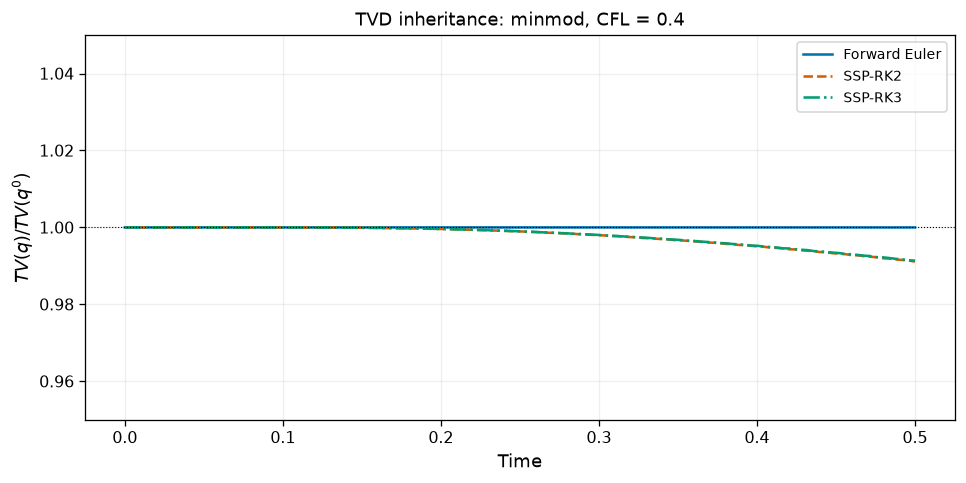

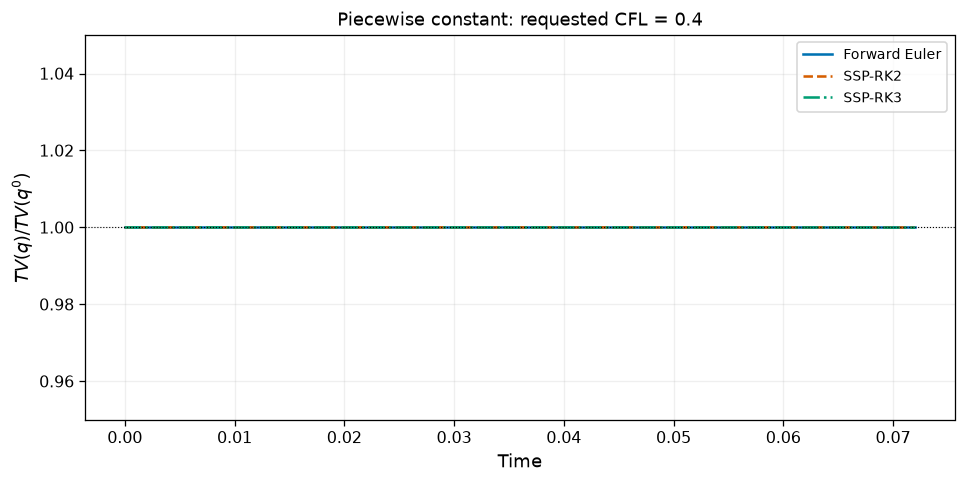

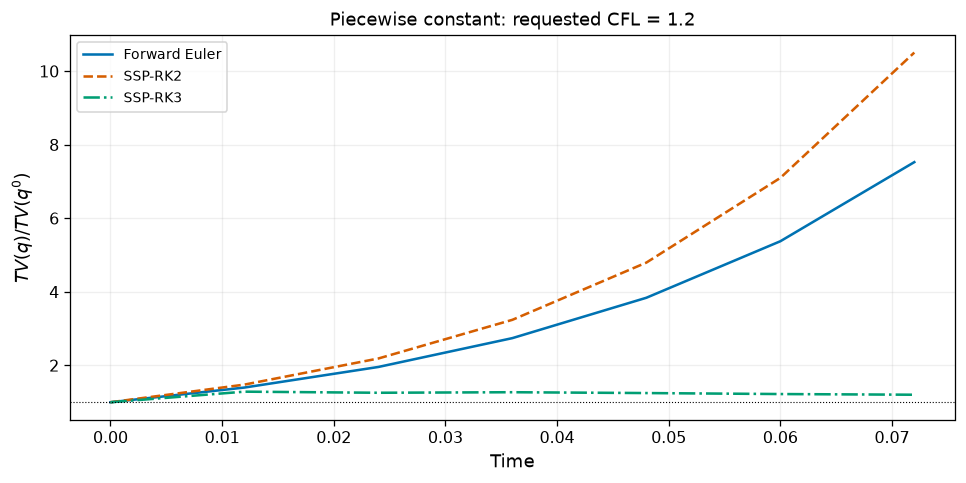

method,TV_initial,TV_final,max_step_increase,steps_with_increase,TV_check_tol,max_mean_drift,q_min,q_max,reconstruction,CFL
Forward Euler,2,2,0,0,2e-11,8.327e-17,0,1,minmod,0.4
SSP-RK2,2,1.982,0,0,2e-11,8.327e-17,0,1,minmod,0.4
SSP-RK3,2,1.983,0,0,2e-11,9.437e-16,0,1,minmod,0.4
Forward Euler,2,2,2.22e-16,0,2e-11,5.551e-17,0,1,constant,0.4
SSP-RK2,2,2,0,0,2e-11,2.776e-17,0,1,constant,0.4
SSP-RK3,2,2,0,0,2e-11,1.665e-16,0,1,constant,0.4
Forward Euler,2,15.06,4.303,6,1.506e-10,0,-1.986,2.986,constant,1.2
SSP-RK2,2,21.02,6.817,6,2.102e-10,0,-0.5072,1.507,constant,1.2
SSP-RK3,2,2.409,0.576,2,2.576e-11,5.551e-17,-0.01398,1.014,constant,1.2
"SSP-RK3, unlimited",2,2.516,0.384,64,2.575e-11,8.882e-16,-0.1043,1.104,unlimited,0.4


In [3]:
import tvd_study as tvd
import scalar1d as sc

TVD_CFG = {
    "n": 100,
    "cfl": 0.4,
    "t_end": 0.5,
    "counterexample_cfl": 1.2,
    "counterexample_steps": 6,
}
if CFG["run_tvd"]:
    edges = np.linspace(0.0, 1.0, TVD_CFG["n"] + 1)
    q0 = sc.exact_cell_average(sc.CASES["advection_box"], edges, 0.0)
    tvd_rows, tvd_histories = [], []
    for ti in tvd.INTEGRATORS:
        run = tvd.simulate(q0, reconstruction="minmod", integrator=ti, cfl=TVD_CFG["cfl"], t_end=TVD_CFG["t_end"])
        label = mol.TIME_LABELS[ti]
        tvd_histories.append((label, run["times"], run["states"]))
        tvd_rows.append(dict(tvd.diagnostics(run["times"], run["states"], label), reconstruction="minmod", CFL=run["CFL"]))
    tvd.plot_histories(tvd_histories, "TVD inheritance: minmod, CFL = 0.4")
    # All time methods have the same dt within each comparison.
    short_end = TVD_CFG["counterexample_steps"] * TVD_CFG["counterexample_cfl"] / TVD_CFG["n"]
    for cfl in (0.4, TVD_CFG["counterexample_cfl"]):
        histories = []
        for ti in tvd.INTEGRATORS:
            run = tvd.simulate(q0, reconstruction="constant", integrator=ti, cfl=cfl, t_end=short_end)
            label = mol.TIME_LABELS[ti]
            histories.append((label, run["times"], run["states"]))
            tvd_rows.append(dict(tvd.diagnostics(run["times"], run["states"], label), reconstruction="constant", CFL=run["CFL"]))
        tvd.plot_histories(histories, f"Piecewise constant: requested CFL = {cfl:g}")
    unlimited = tvd.simulate(q0, reconstruction="unlimited", integrator="ssprk3", cfl=0.4, t_end=TVD_CFG["t_end"])
    tvd_rows.append(dict(tvd.diagnostics(unlimited["times"], unlimited["states"], "SSP-RK3, unlimited"), reconstruction="unlimited", CFL=unlimited["CFL"]))
    show_table(tvd_rows)
    if CFG["export_results"]:
        tvd.export_diagnostics(tvd_rows, OUTPUT_DIR / "tvd_time_integrators.csv")


### 2.7 全変動・値の範囲・波面幅を分けて確認する

周期的な配列には

$$TV(q)\ge2\left(\max_i q_i-\min_i q_i\right)$$

が成り立ちます。最小値から最大値へ進む区間と、最大値から最小値へ戻る区間で、それぞれ少なくとも最大値と最小値の差だけ変化するためです。

等号は、周期的に一周したとき、最小値から最大値までは単調非減少、最大値から最小値までは単調非増加となる場合に成り立ちます。平坦部を許し、一様な分布も含みます。例えば$(0,0,1,1)$と$(1/4,3/4,1/4,3/4)$はどちらも$TV=2$ですが、後者では$TV>2(\max-\min)$です。TVの数値だけでは振動や極値を判定できません。

次の表は、上のminmod・CFL 0.4の計算について、最終時刻の最小・最大値と、全ステップでの$TV-2(\max-\min)$を表示します。波面の幅は、$0.1<q<0.9$となるセルの合計長`mixed_length_final`で別に評価します。これは2つの遷移層の合計長で、波面位置そのものではありません。複数の山を持つ物理的な波形では、正の$TV-2(\max-\min)$が直ちに数値振動を意味するわけではない点も確認してください。

In [4]:
import review_experiments as review
if CFG["run_tvd"]:
    TABLES["tv_range_checks"] = review.tv_shape_diagnostics(n=TVD_CFG["n"], cfl=TVD_CFG["cfl"], t_end=TVD_CFG["t_end"])

integrator,TV_final,q_min_final,q_max_final,max_TV_minus_2range,min_TV_minus_2range,mixed_length_final
forward_euler,2,1.146e-32,1,4.441e-16,-4.441e-16,0.04
ssprk2,1.982,1.23e-17,0.9911,4.441e-16,-4.441e-16,0.16
ssprk3,1.983,1.856e-17,0.9914,4.441e-16,-4.441e-16,0.16


## 3. 時間誤差と空間誤差を分ける

連続方程式の厳密解と比較した誤差 $E_{\rm total}$ には空間離散化誤差も含まれます。時間刻みを小さくしても、この誤差が一定値へ近づくことがあります。

時間積分だけを見るため、**同じ半離散系**を非常に細かい時間刻みで積分した数値参照解 $U_{\rm ref}$ と比較します。

$$E_{\mathrm{time}}(\Delta t)=\frac1N\sum_i|\bar\rho_{\Delta t,i}(T)-\bar\rho_{{\rm ref},i}(T)|,$$
$$p_t=\frac{\log(E_{\mathrm{time}}(\Delta t_1)/E_{\mathrm{time}}(\Delta t_2))}{\log(\Delta t_1/\Delta t_2)}.$$

参照解は各流束について別々に計算します。細かい**空間格子**の解を使うのではありません。
2つの細かい時間刻みの参照解の差 `reference_gap` と、測定した最小誤差との比 `gap_over_error` も表示します。比が0.05以上なら参照解不足の警告を出します。この判定だけで参照解の誤差を厳密に保証したことにはなりません。

固定ステップ数 $N_t$ から $\Delta t=T/N_t$ を決め、全時間積分法で同じ刻みを使います。CFL上限を超える設定は停止し、勝手に刻みを変更しません。
`temporal_n`や終了時刻を大きくしたときは、`temporal_steps`と`reference_steps`も十分大きくしてください。

**予想：** 滑らかな半離散解に対して、時間積分次数は1・2・3です。ただし、勾配制限などで右辺の滑らかさが失われる場合や丸め誤差・参照誤差が支配する場合は、この次数がそのまま観測されるとは限りません。

### 3.1 なぜ、厳密解との誤差だけでは時間精度が分からないのか

格子を固定したまま時間刻みを非常に小さくしても、空間を有限個のセルで表した誤差は消えません。例えば数値波形が空間的な散逸でなまっていれば、時間積分だけを精密にしても、そのなまりは残ります。

そこで、次の二つを区別します。

| 指標 | 比較相手 | 主に調べること |
|:--|:--|:--|
| `E_total` | 連続方程式の厳密解をセル平均したもの | 空間・時間を合わせた誤差 |
| `E_time` | 同じ格子・流束・再構築で、時間刻みを十分細かくした数値参照解 | 同じ半離散系に対する時間積分の誤差 |

時間参照解も厳密な解ではありません。そのため、さらに細かい時間刻みの参照解と比べ、参照解同士の差が評価したい誤差より十分小さいかを確認します。

**RK3を使っても空間再構築が2次なら、通常の$\Delta t\propto\Delta x$の試験で全体が3次になるわけではありません。** 時間誤差が小さくなり空間誤差が支配すると、`E_time`は下がっても`E_total`はほとんど下がらないことがあります。次の図は、まさにこの違いを読むためのものです。

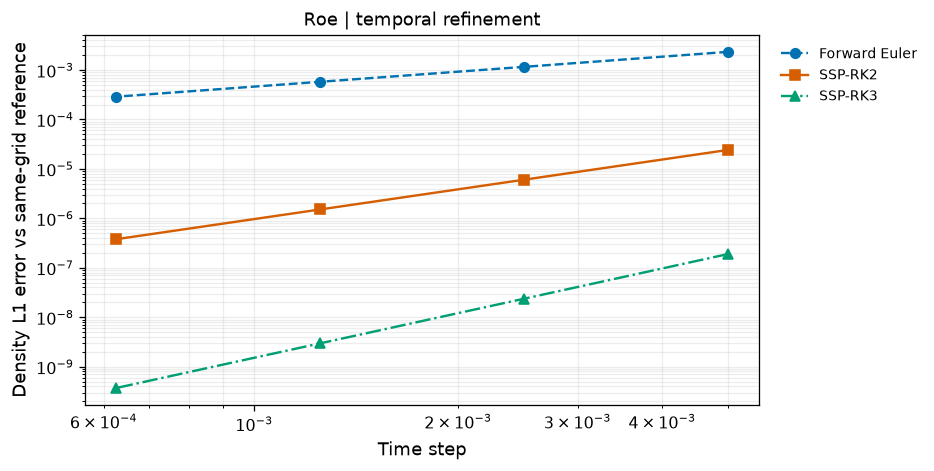

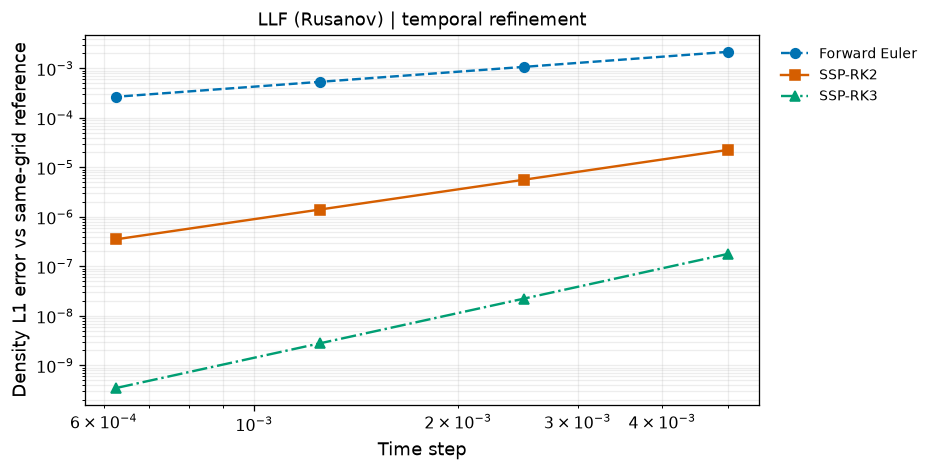

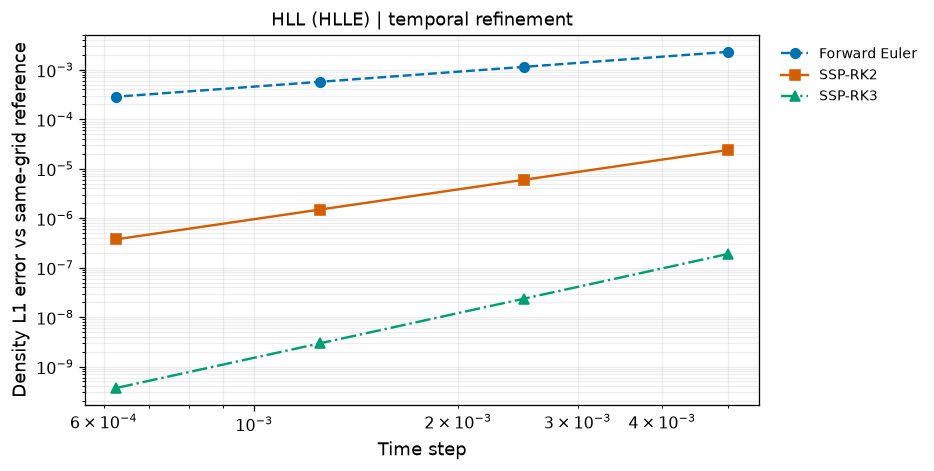

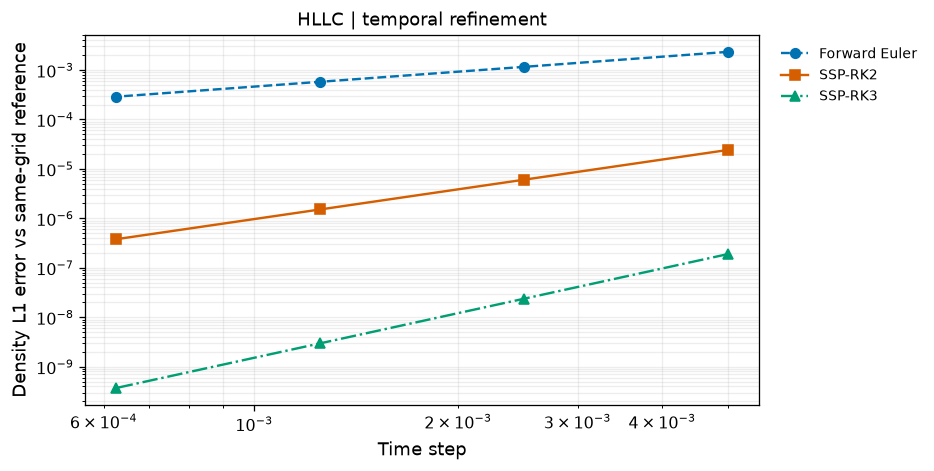

flux,reference_steps_coarse,reference_steps_fine,reference_gap,minimum_measured_error,gap_over_error,reference_resolved
Roe,1280,2560,5.065e-12,3.695e-10,0.01371,True
LLF (Rusanov),1280,2560,4.763e-12,3.476e-10,0.0137,True
HLL (HLLE),1280,2560,5.046e-12,3.681e-10,0.01371,True
HLLC,1280,2560,5.065e-12,3.695e-10,0.01371,True


flux,time_integrator,steps,dt,E_time,q_time,E_total,status,n_rhs
Roe,forward_euler,40,0.005,0.002334,—,0.007715,ok,40
Roe,forward_euler,80,0.0025,0.00116,1.009,0.008888,ok,80
Roe,forward_euler,160,0.00125,0.0005785,1.004,0.00947,ok,160
Roe,forward_euler,320,0.000625,0.0002889,1.002,0.00976,ok,320
Roe,ssprk2,40,0.005,2.423e-05,—,0.01005,ok,80
Roe,ssprk2,80,0.0025,6.053e-06,2.001,0.01005,ok,160
Roe,ssprk2,160,0.00125,1.513e-06,2.001,0.01005,ok,320
Roe,ssprk2,320,0.000625,3.781e-07,2,0.01005,ok,640
Roe,ssprk3,40,0.005,1.899e-07,—,0.01005,ok,120
Roe,ssprk3,80,0.0025,2.371e-08,3.002,0.01005,ok,240


flux,tolerance,time_integrator,n_rhs,seconds,achieved_error
Roe,0.001,forward_euler,160,0.08713,0.0005785
Roe,0.001,ssprk2,80,0.04562,2.423e-05
Roe,0.001,ssprk3,120,0.05704,1.899e-07
Roe,1e-05,forward_euler,None,None,None
Roe,1e-05,ssprk2,160,0.09536,6.053e-06
Roe,1e-05,ssprk3,120,0.05704,1.899e-07
Roe,1e-07,forward_euler,None,None,None
Roe,1e-07,ssprk2,None,None,None
Roe,1e-07,ssprk3,240,0.134,2.371e-08
LLF (Rusanov),0.001,forward_euler,160,0.07163,0.0005337


In [5]:
if CFG["run_time_convergence"]:
    time_rows, reference_rows = ex.temporal_convergence(CFG)
    TABLES["temporal_convergence"] = time_rows
    TABLES["temporal_reference_checks"] = reference_rows
    TABLES["cost_at_tolerance"] = ex.cost_table(time_rows)

### 3.2 結果の読み方

`E_time`は同じ空間離散化の参照解との差、`E_total`は連続方程式の厳密解との差です。両者の大小・時間刻み依存性を比較してください。
`n_rhs`は右辺評価回数で、途中で失敗した試行も数えます。`seconds`はこの環境での実測時間であり、短い計算ではばらつきます。
コスト表は**計算済みの候補の中で**誤差目標を満たす最小`n_rhs`を選びます。`None`は未達です。すべての刻みを探索した最適コストではありません。

**確認：** SSP-RK3の`E_time`が小さくても、`E_total`は必ずSSP-RK2より小さくなるでしょうか。誤差の相殺と空間誤差の下限を区別してください。

<details>
<summary>時間誤差の確認問題：解答</summary>

SSP-RK3の$E_{\mathrm{time}}$が小さくても、$E_{\mathrm{total}}$まで必ず小さくなるとは限りません。前者は同じ半離散系への近さ、後者は連続方程式の厳密解への近さです。空間誤差と時間誤差の符号による相殺や、空間誤差が支配する下限があるためです。

</details>

### 3.3 MUSCLでも時間収束を測る

ここまでの区分一定の試験に続き、同じ格子・HLLC流束で、制限なし線形再構築・minmod・MCをそれぞれ固定して時間刻みだけを細かくします。各再構築について、参照解も同じ空間離散化で計算します。

高次RK法の通常の誤差解析は、半離散系の右辺$\mathcal L$が十分滑らかであることを仮定します。minmod・MCは符号や最小値で場合分けするため、その分岐の切替点では微分可能性が失われる場合があります。観測次数が下がったり、格子や時間刻みで変わったりするかを調べます。「minmodなら一定の約2.7次」という普遍的な次数を測る演習ではありません。

参照計算はSSP-RK3の5,120・10,240ステップを標準とし、参照解同士の差が最小測定誤差の5%未満かを表で確認します。条件を変えて警告が出たら、参照計算をさらに細かくします。基準を通ることは精度診断であり、参照誤差の厳密な上界の証明ではありません。

Same-grid temporal convergence: MUSCL + unlimited


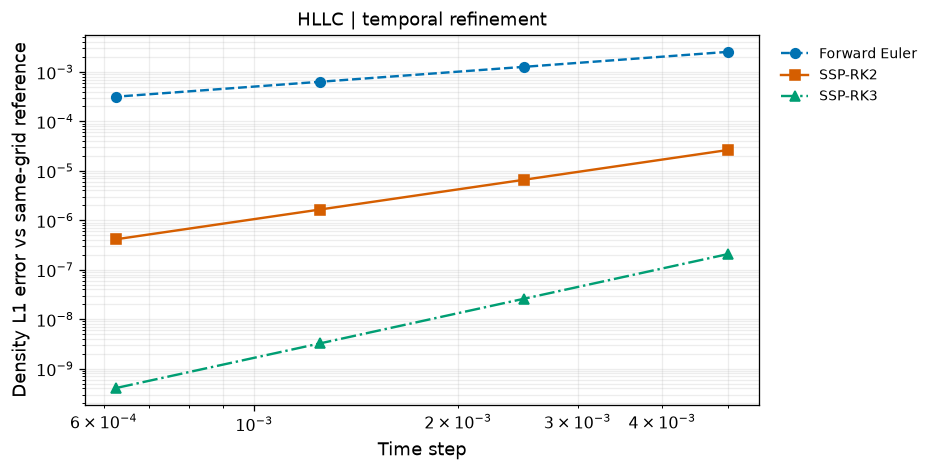

flux,reference_steps_coarse,reference_steps_fine,reference_gap,minimum_measured_error,gap_over_error,reference_resolved
HLLC,5120,10240,1.895e-13,4.053e-10,0.0004676,True


flux,time_integrator,steps,dt,E_time,q_time,E_total,status,n_rhs
HLLC,forward_euler,40,0.005,0.002539,—,0.002504,ok,40
HLLC,forward_euler,80,0.0025,0.001264,1.007,0.00124,ok,80
HLLC,forward_euler,160,0.00125,0.0006305,1.003,0.000627,ok,160
HLLC,forward_euler,320,0.000625,0.0003149,1.002,0.0003522,ok,320
HLLC,ssprk2,40,0.005,2.638e-05,—,0.0002561,ok,80
HLLC,ssprk2,80,0.0025,6.593e-06,2,0.0002367,ok,160
HLLC,ssprk2,160,0.00125,1.649e-06,2,0.0002319,ok,320
HLLC,ssprk2,320,0.000625,4.123e-07,2,0.0002307,ok,640
HLLC,ssprk3,40,0.005,2.075e-07,—,0.0002303,ok,120
HLLC,ssprk3,80,0.0025,2.593e-08,3,0.0002303,ok,240


Same-grid temporal convergence: MUSCL + minmod


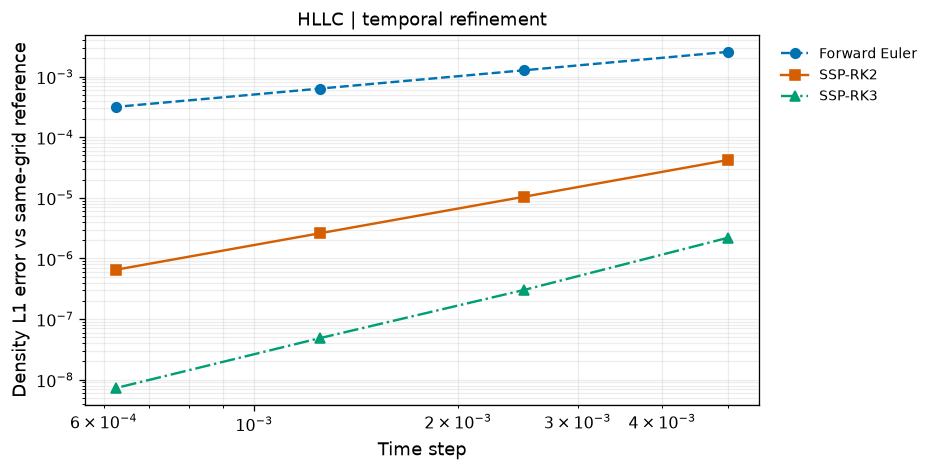

flux,reference_steps_coarse,reference_steps_fine,reference_gap,minimum_measured_error,gap_over_error,reference_resolved
HLLC,5120,10240,3.18e-11,7.284e-09,0.004366,True


flux,time_integrator,steps,dt,E_time,q_time,E_total,status,n_rhs
HLLC,forward_euler,40,0.005,0.002555,—,0.002911,ok,40
HLLC,forward_euler,80,0.0025,0.001269,1.01,0.002065,ok,80
HLLC,forward_euler,160,0.00125,0.0006329,1.004,0.001695,ok,160
HLLC,forward_euler,320,0.000625,0.000316,1.002,0.00156,ok,320
HLLC,ssprk2,40,0.005,4.206e-05,—,0.001482,ok,80
HLLC,ssprk2,80,0.0025,1.041e-05,2.015,0.00147,ok,160
HLLC,ssprk2,160,0.00125,2.603e-06,2,0.001468,ok,320
HLLC,ssprk2,320,0.000625,6.512e-07,1.999,0.001467,ok,640
HLLC,ssprk3,40,0.005,2.197e-06,—,0.001466,ok,120
HLLC,ssprk3,80,0.0025,3.023e-07,2.862,0.001467,ok,240


Same-grid temporal convergence: MUSCL + mc


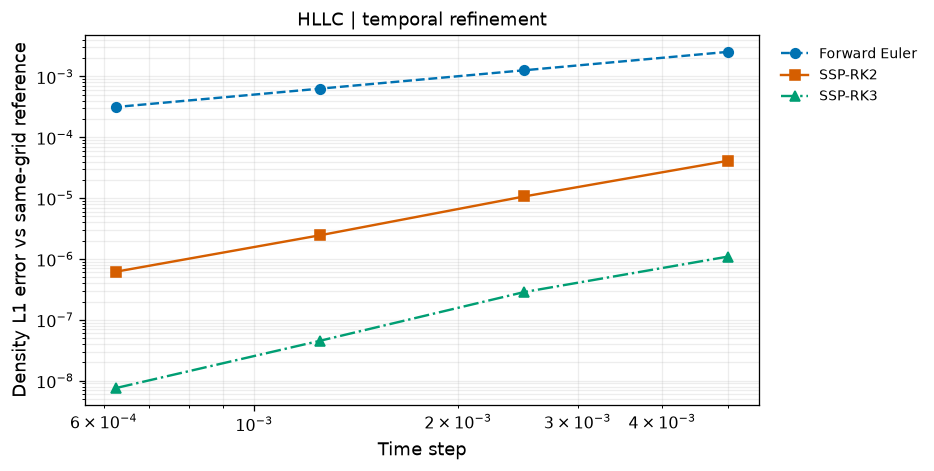

flux,reference_steps_coarse,reference_steps_fine,reference_gap,minimum_measured_error,gap_over_error,reference_resolved
HLLC,5120,10240,3.497e-11,7.561e-09,0.004625,True


flux,time_integrator,steps,dt,E_time,q_time,E_total,status,n_rhs
HLLC,forward_euler,40,0.005,0.00254,—,0.002553,ok,40
HLLC,forward_euler,80,0.0025,0.001264,1.007,0.001346,ok,80
HLLC,forward_euler,160,0.00125,0.0006305,1.003,0.0008173,ok,160
HLLC,forward_euler,320,0.000625,0.0003149,1.002,0.0005923,ok,320
HLLC,ssprk2,40,0.005,4.117e-05,—,0.0005545,ok,80
HLLC,ssprk2,80,0.0025,1.065e-05,1.95,0.0005245,ok,160
HLLC,ssprk2,160,0.00125,2.453e-06,2.119,0.0005169,ok,320
HLLC,ssprk2,320,0.000625,6.179e-07,1.989,0.0005151,ok,640
HLLC,ssprk3,40,0.005,1.097e-06,—,0.0005152,ok,120
HLLC,ssprk3,80,0.0025,2.859e-07,1.939,0.0005146,ok,240


In [6]:
if CFG["run_time_convergence"]:
    for limiter_name in ("unlimited", "minmod", "mc"):
        limited_cfg = dict(CFG, temporal_reconstruction="muscl", temporal_limiter=limiter_name, fluxes=("HLLC",), reference_steps=(5120, 10240))
        print("Same-grid temporal convergence: MUSCL +", limiter_name)
        limited_rows, limited_refs = ex.temporal_convergence(limited_cfg)
        TABLES["time_muscl_" + limiter_name] = limited_rows
        TABLES["reference_muscl_" + limiter_name] = limited_refs

## 4. 安定性と精度は別の性質

試験方程式 $\frac{dy}{dt}=\lambda y$ に対し、$y^{n+1}=R(z)y^n$、$z=\lambda\Delta t$と書けます。

$$R_{\rm FE}=1+z,\qquad R_{\rm RK2}=1+z+\tfrac12z^2,\qquad R_{\rm RK3}=1+z+\tfrac12z^2+\tfrac16z^3.$$

純虚数 $z=i\beta$ に限れば、前進EulerとSSP-RK2は$\beta\ne0$で$|R|>1$、SSP-RK3は$|\beta|\le\sqrt3$に安定な区間を持ちます。
これは**純虚数軸上の線形安定性**の比較です。散逸を含む実際の空間離散化の固有値は一般に純虚数ではなく、下図だけから非線形Euler系の安定CFL数を決めることはできません。[T1]

### 4.1 安定性は「誤差が小さいこと」と同じではない

丸め誤差や離散化誤差は計算中に少しずつ生じます。安定性は、それらが更新を繰り返す中でどのように増幅されるかを扱います。精度は正しい解への近さです。安定でも大きくなまる計算があり、高い次数の式でも時間刻みが不適切なら破綻します。

次の試験方程式では、$R$を**1ステップでの増幅率**と考えます。$|R|=1$ならそのモードの振幅を保ち、$|R|>1$なら増やします。図の横軸は空間座標ではなく、時間刻みとモードの振動速度を組み合わせた量です。

この単純な試験の安定性、非線形なTVD性、密度・圧力の正値性は別の条件です。「この図で安定だから任意のEuler計算も安定」とは判断しません。

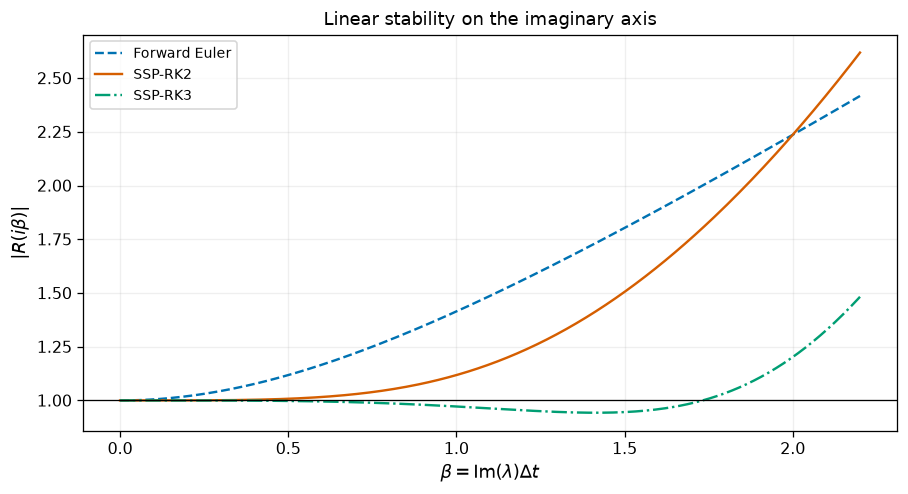

In [7]:
beta = np.linspace(0.0, 2.2, 301)
z = 1j * beta
amplification = (np.abs(1 + z), np.abs(1 + z + z**2 / 2), np.abs(1 + z + z**2 / 2 + z**3 / 6))
fig = plt.figure(figsize=(8.0, 4.4))
ax = fig.gca()
for j, ti in enumerate(mol.TIME_INTEGRATORS):
    ax.plot(beta, amplification[j], color=ex.COLORS[j], ls=ex.STYLES[j], label=mol.TIME_LABELS[ti])
ax.axhline(1.0, color="black", lw=0.8)
ax.set(xlabel=r"$\beta=\mathrm{Im}(\lambda)\Delta t$", ylabel=r"$|R(i\beta)|$", title="Linear stability on the imaginary axis")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
plt.close(fig)

## 5. 同じMUSCLでの滑らかな波の移流

ここからは設定のreconstructionとlimiterを固定し、時間積分を変えます。標準はMUSCL＋minmodです。CFL規則は共通ですが、実際の時間刻みが同一とは限りません。

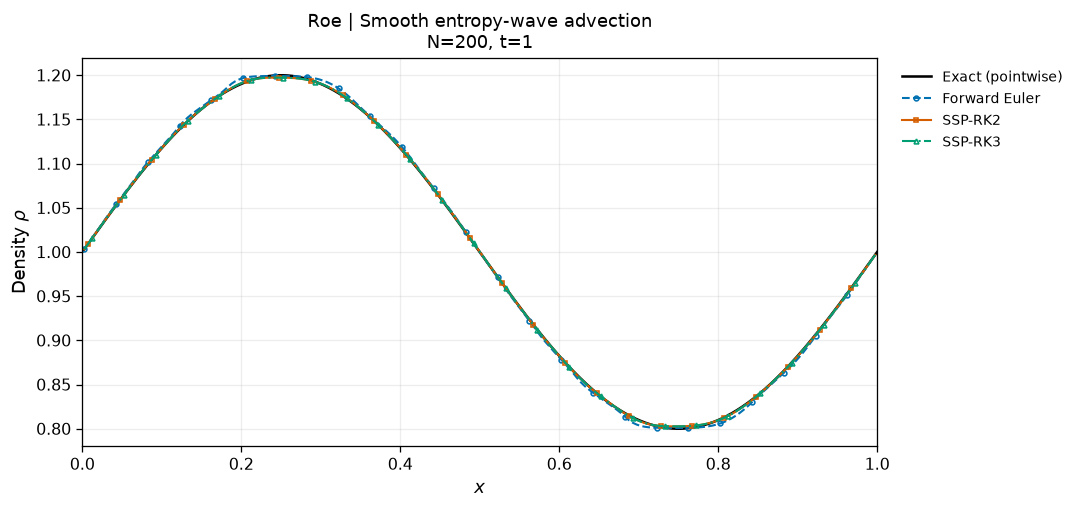

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
Roe,muscl,minmod,forward_euler,ok,1,0.002231,1,2.22e-15,1162,0.5447
Roe,muscl,minmod,ssprk2,ok,1,0.0005035,1,6.661e-16,2322,0.997
Roe,muscl,minmod,ssprk3,ok,1,0.0005026,1,1.315e-13,3483,1.444


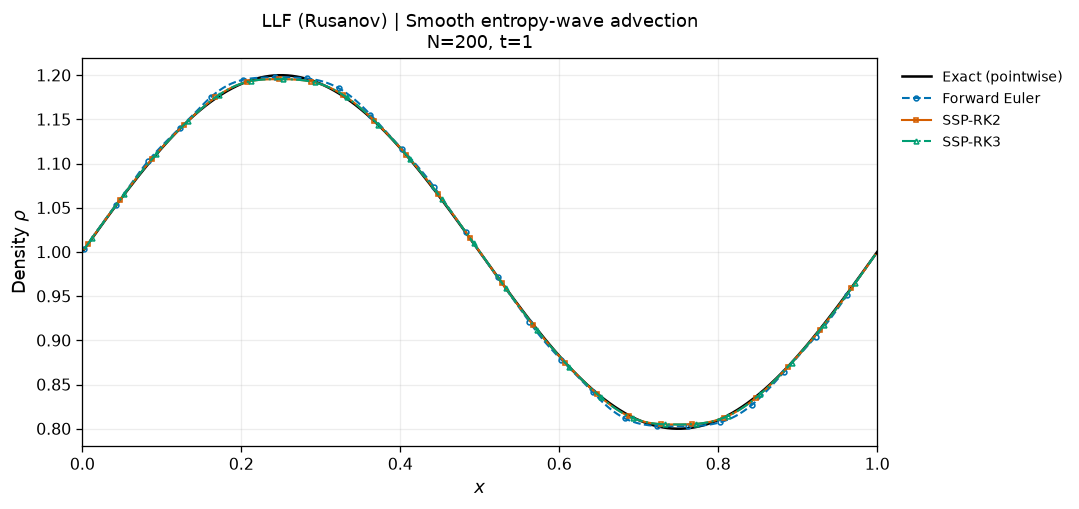

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
LLF,muscl,minmod,forward_euler,ok,1,0.002477,1,2.22e-15,1161,0.4094
LLF,muscl,minmod,ssprk2,ok,1,0.001034,1,1.332e-15,2322,0.7519
LLF,muscl,minmod,ssprk3,ok,1,0.001033,1,1.297e-13,3483,1.106


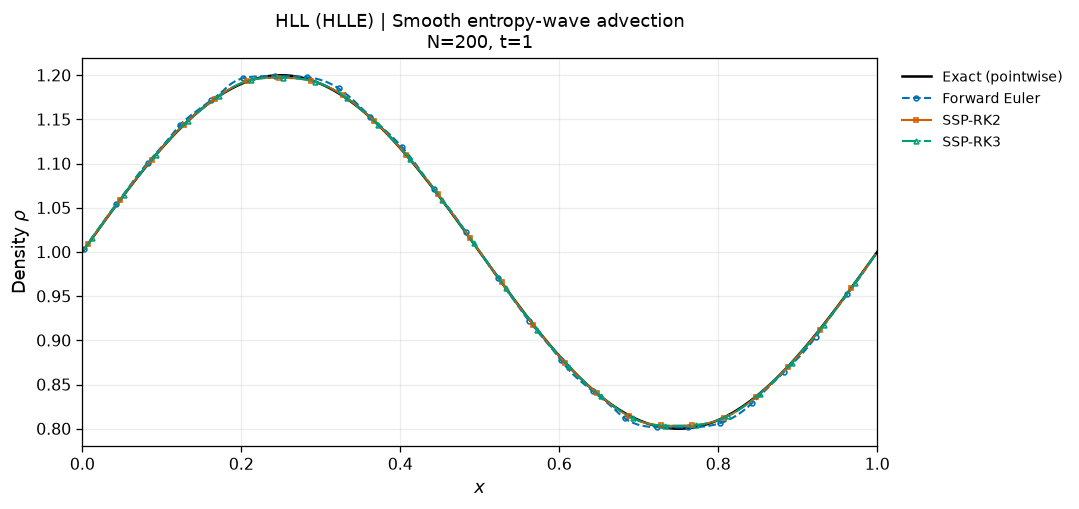

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLL,muscl,minmod,forward_euler,ok,1,0.002276,1,2.22e-15,1162,0.472
HLL,muscl,minmod,ssprk2,ok,1,0.0005896,1,8.882e-16,2322,0.8867
HLL,muscl,minmod,ssprk3,ok,1,0.0005887,1,1.301e-13,3483,1.327


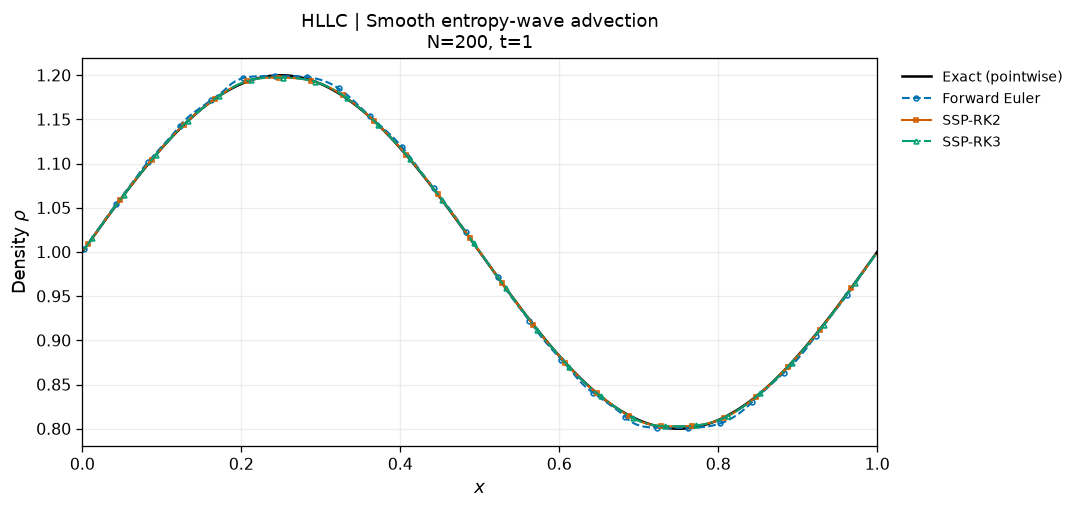

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLLC,muscl,minmod,forward_euler,ok,1,0.002231,1,2.665e-15,1162,0.5956
HLLC,muscl,minmod,ssprk2,ok,1,0.0005035,1,4.441e-16,2322,1.12
HLLC,muscl,minmod,ssprk3,ok,1,0.0005026,1,1.332e-13,3483,1.653


In [8]:
for flux in CFG["fluxes"]:
    runs = ex.group_runs("entropy", flux, CFG, "time")
    ex.plot_group(runs, "time", fields=("rho",))
    ex.summarize(runs)

## 6. 接触不連続面

低散逸の空間再構築に前進Eulerを組み合わせたとき、振動や拡散がどのように現れるかを確認します。滑らかな問題で測った次数を、不連続面での局所次数と混同しないでください。

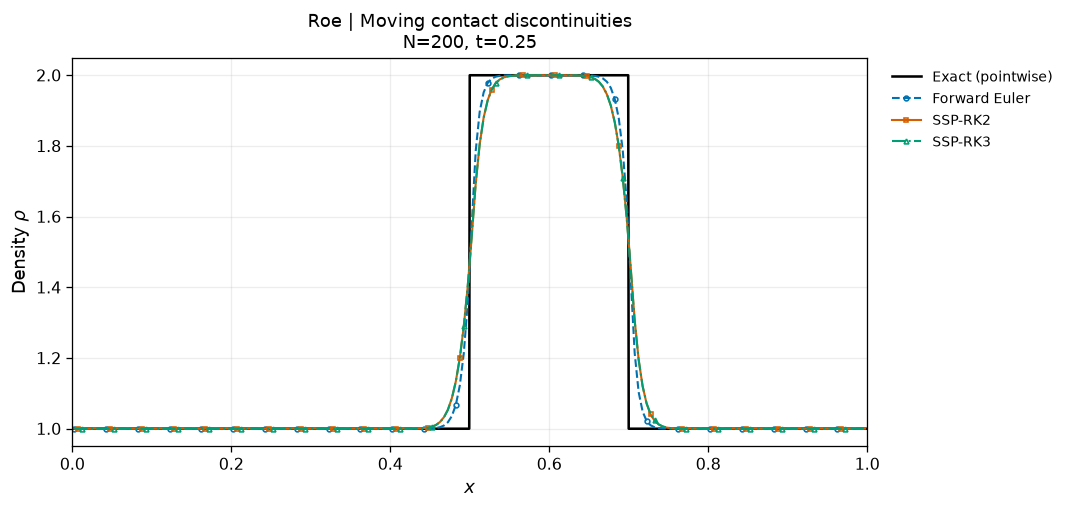

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
Roe,muscl,minmod,forward_euler,ok,0.25,0.01659,1,4.441e-16,273,0.1244
Roe,muscl,minmod,ssprk2,ok,0.25,0.0248,1,8.882e-16,546,0.2335
Roe,muscl,minmod,ssprk3,ok,0.25,0.02475,1,1.821e-14,819,0.3437


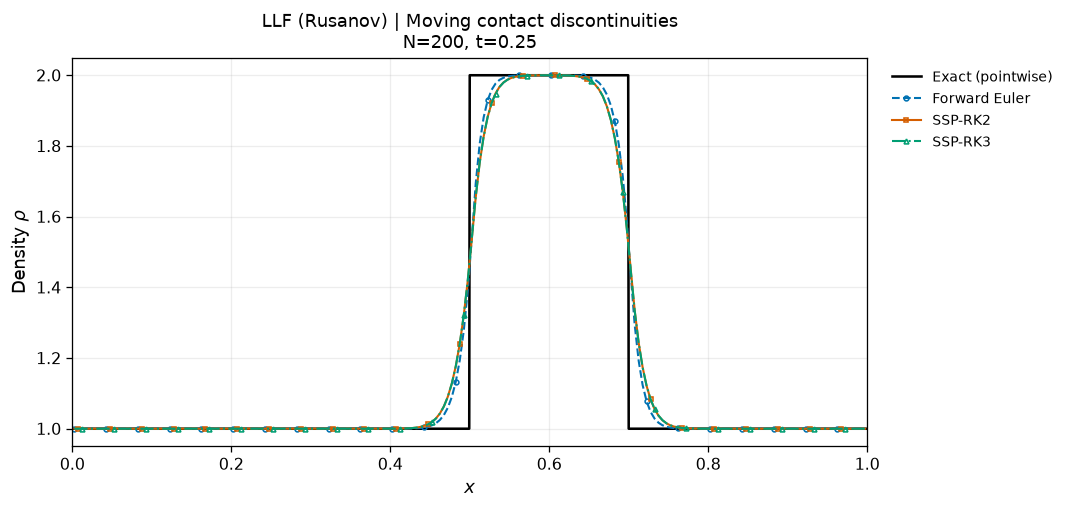

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
LLF,muscl,minmod,forward_euler,ok,0.25,0.02492,1,1.776e-15,273,0.09812
LLF,muscl,minmod,ssprk2,ok,0.25,0.03129,1,2.22e-15,546,0.1786
LLF,muscl,minmod,ssprk3,ok,0.25,0.03127,1,2.398e-14,819,0.2728


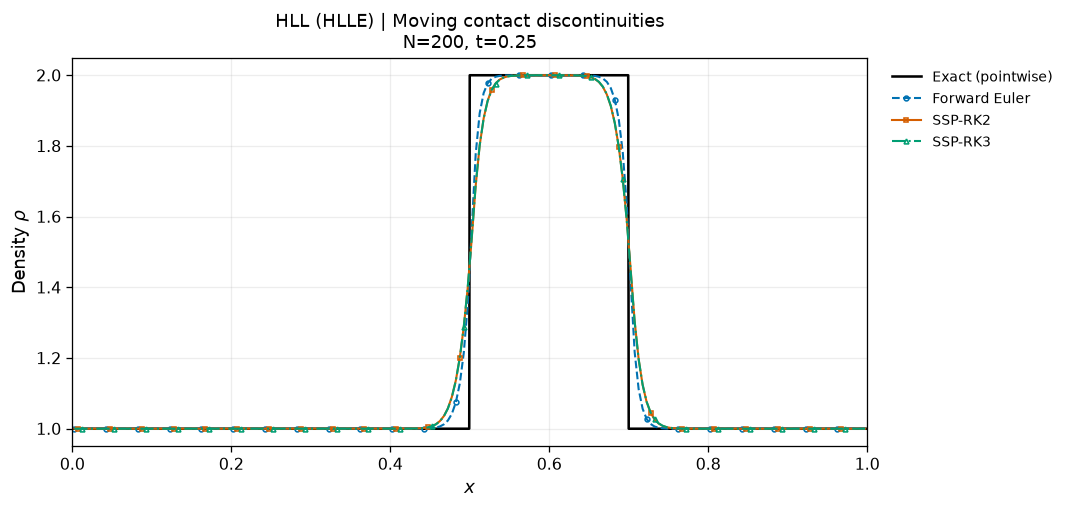

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLL,muscl,minmod,forward_euler,ok,0.25,0.01707,1,4.441e-16,273,0.1113
HLL,muscl,minmod,ssprk2,ok,0.25,0.02514,1,8.882e-16,546,0.2105
HLL,muscl,minmod,ssprk3,ok,0.25,0.02509,1,1.643e-14,819,0.3082


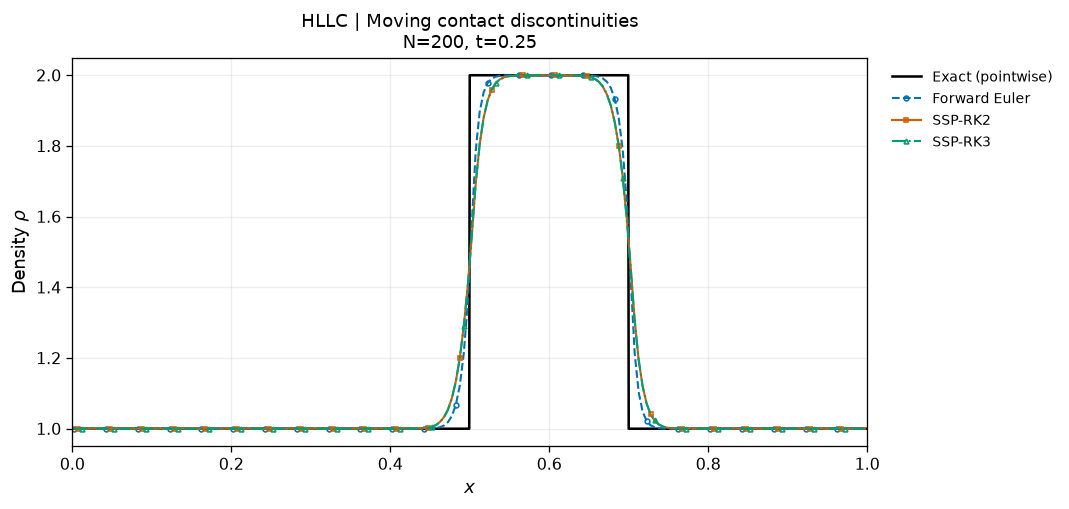

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLLC,muscl,minmod,forward_euler,ok,0.25,0.01659,1,8.882e-16,273,0.1404
HLLC,muscl,minmod,ssprk2,ok,0.25,0.0248,1,8.882e-16,546,0.2625
HLLC,muscl,minmod,ssprk3,ok,0.25,0.02475,1,1.643e-14,819,0.3889


In [9]:
for flux in CFG["fluxes"]:
    runs = ex.group_runs("contact", flux, CFG, "time")
    ex.plot_group(runs, "time", fields=("rho",))
    ex.summarize(runs)

## 7. Sod衝撃波管

同じ流束・再構築で時間積分だけを変えます。途中段階の負圧などで停止した場合も結果として記録します。

**見る順番：** 同じ流束の図の中で、3種類の時間積分の曲線を比較します。衝撃波の位置、接触面の幅、余分な振動を分けて見て、停止した計算があれば表の理由を確認します。不連続を含むこの比較だけから、時間の形式的な収束次数1・2・3を測ることはしません。

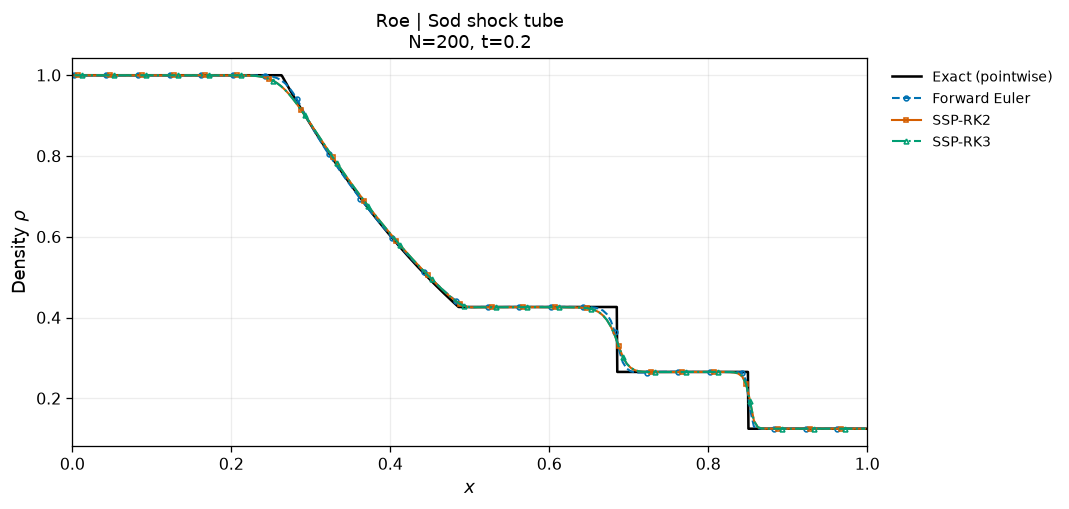

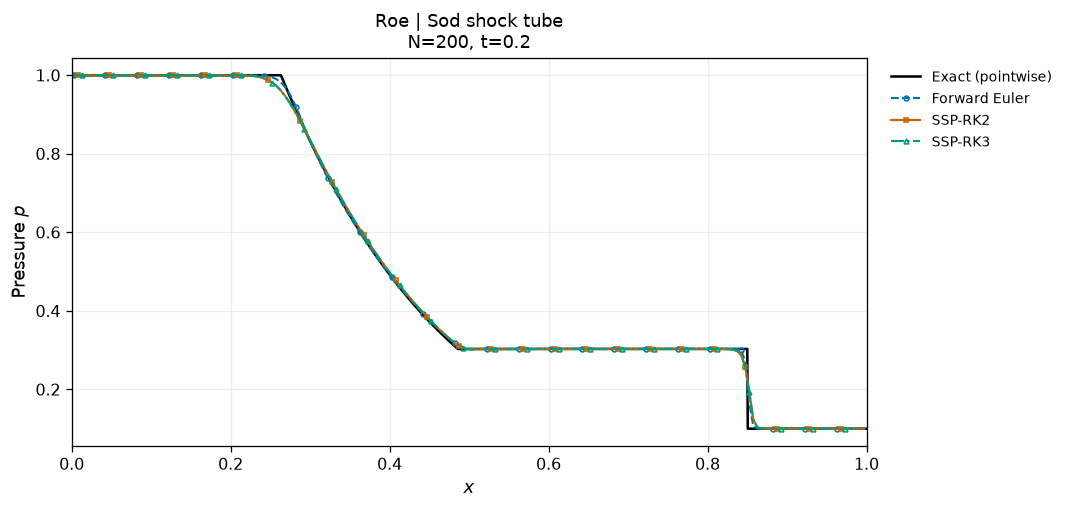

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
Roe,muscl,minmod,forward_euler,ok,0.2,0.002374,0.1,1.11e-15,219,0.1022
Roe,muscl,minmod,ssprk2,ok,0.2,0.003984,0.1,4.441e-16,436,0.1903
Roe,muscl,minmod,ssprk3,ok,0.2,0.003967,0.1,5.329e-15,654,0.28


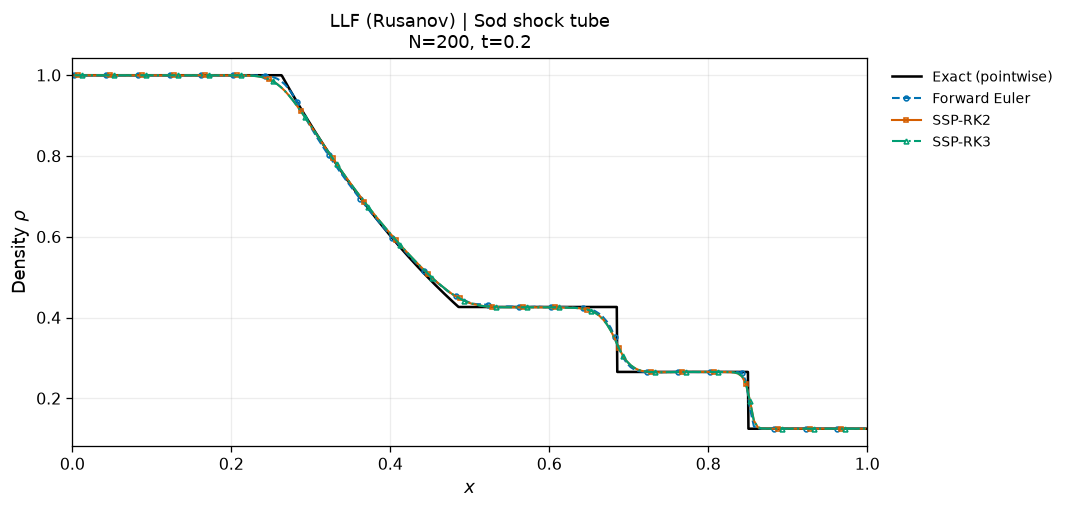

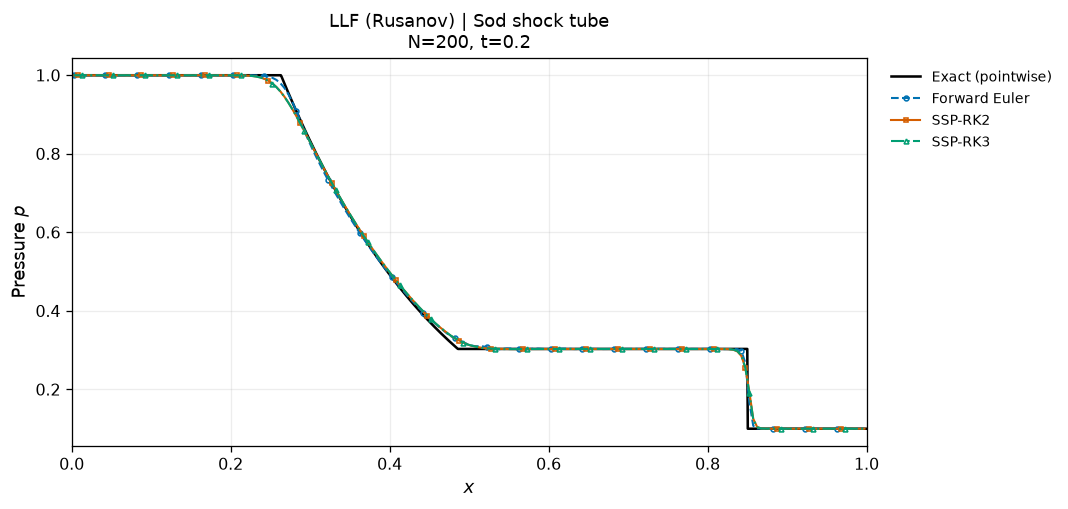

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
LLF,muscl,minmod,forward_euler,ok,0.2,0.004014,0.1,1.11e-16,219,0.07906
LLF,muscl,minmod,ssprk2,ok,0.2,0.005112,0.1,4.441e-16,434,0.1452
LLF,muscl,minmod,ssprk3,ok,0.2,0.005118,0.1,5.551e-15,651,0.213


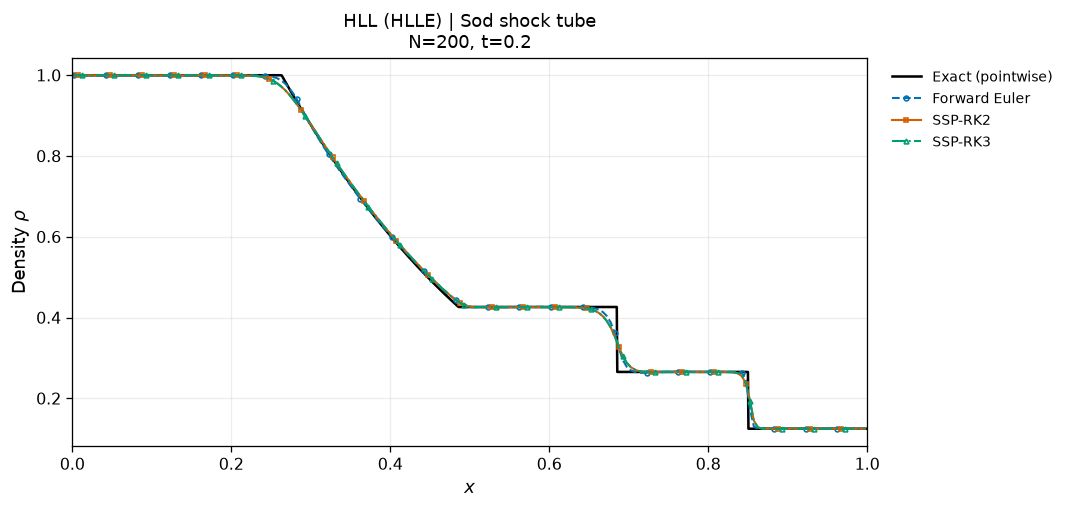

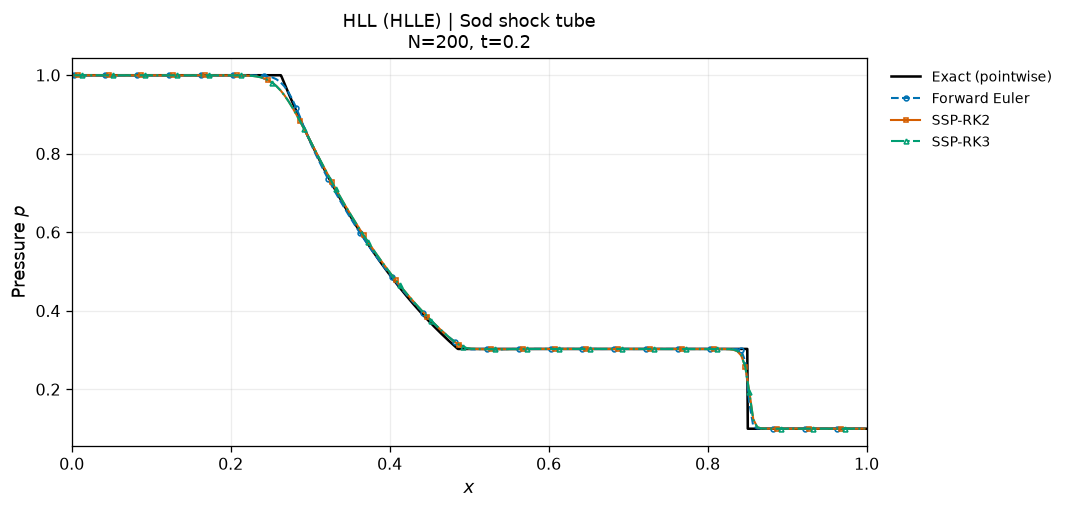

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLL,muscl,minmod,forward_euler,ok,0.2,0.002773,0.1,1.943e-16,219,0.09201
HLL,muscl,minmod,ssprk2,ok,0.2,0.004209,0.1,2.22e-16,434,0.1679
HLL,muscl,minmod,ssprk3,ok,0.2,0.004202,0.1,5.773e-15,651,0.2464


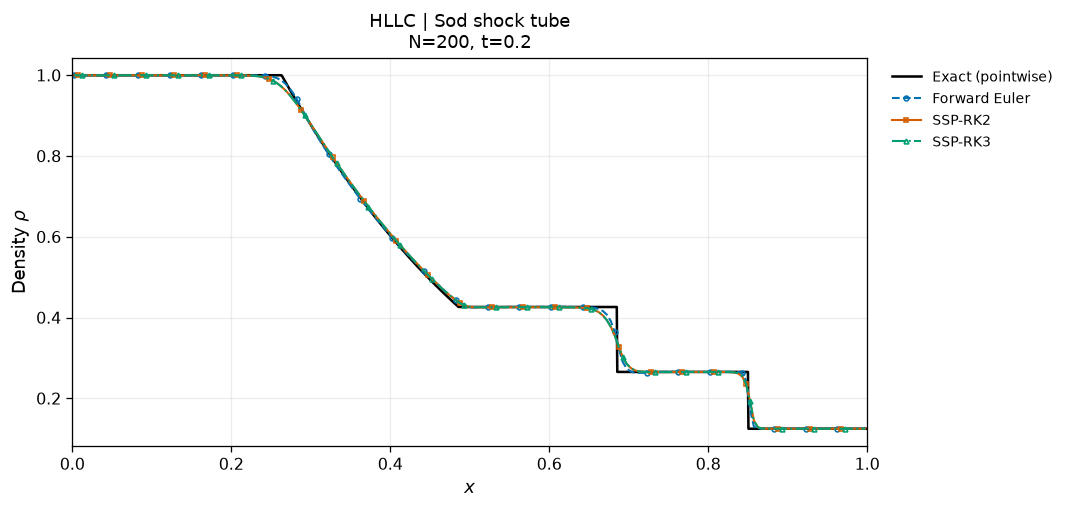

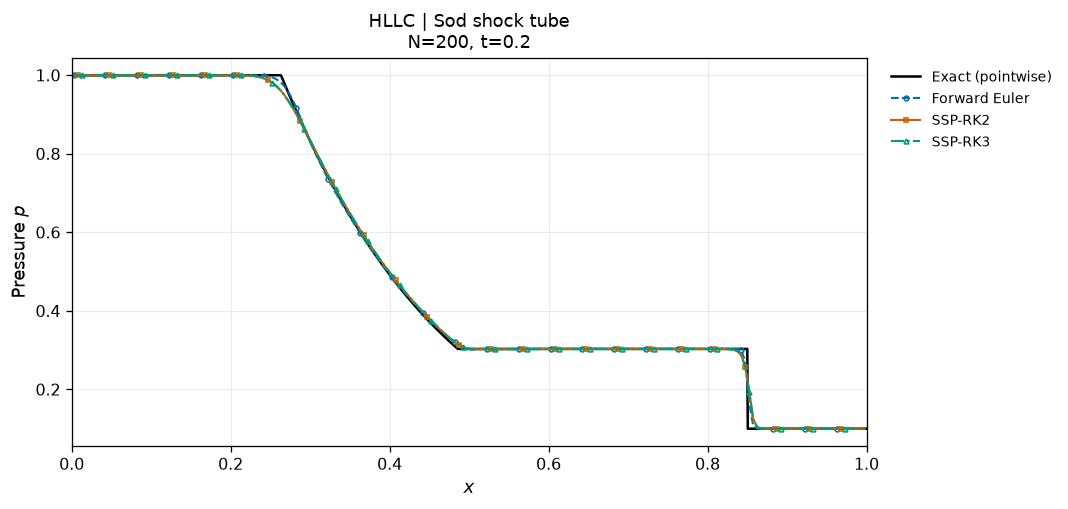

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLLC,muscl,minmod,forward_euler,ok,0.2,0.002581,0.1,2.22e-16,219,0.1124
HLLC,muscl,minmod,ssprk2,ok,0.2,0.004069,0.1,4.441e-16,436,0.2126
HLLC,muscl,minmod,ssprk3,ok,0.2,0.004057,0.1,5.773e-15,654,0.3148


In [10]:
for flux in CFG["fluxes"]:
    runs = ex.group_runs("sod", flux, CFG, "time")
    ex.plot_group(runs, "time", fields=("rho", "p"))
    ex.summarize(runs)

### 7.1 前進Eulerが不連続面で小さい誤差を示す理由

誤差を小さくするには、空間と時間の両方を調べる必要があります。標準設定のMUSCL＋minmodでは、接触面やSodの密度誤差が前進Eulerで小さく、滑らかな波ではRK法で小さくなる場合があります。この逆転を「前進Eulerがいつでも最良」と読むのでなく、誤差の相殺と波形から解釈します。

まず説明用に、滑らかな線形移流、$a>0$を考えます。前進Eulerの時間離散化の主要な誤差は、修正方程式で

$$\frac{\partial q}{\partial t}+a\frac{\partial q}{\partial x}=-\frac{a^2\Delta t}{2}\frac{\partial^2q}{\partial x^2}+\cdots$$

という負の拡散項として現れます。区分一定の風上空間離散化が持つ正の拡散$a\Delta x/2$と合わせると、

$$\nu_{\mathrm{up}}=\frac{a\Delta x}{2}(1-C_{\mathrm{adv}}).$$

時間刻みを小さくすると負の時間誤差が小さくなり、正の空間拡散を打ち消す効果も弱くなります。そのため、同じ格子で$E_{\mathrm{time}}$が減る一方、$E_{\mathrm{total}}$が増えることがあります。時間精度と全体精度を分ける理由です。

MUSCLでも、前進Eulerの時間誤差が波面を鋭く見せることがあります。しかし、不連続点やリミッターの切替では上のTaylor展開が使えないため、これは解釈の手掛かりです。次の表で密度誤差・接触面の遷移幅・行き過ぎを併せて確認します。スカラーminmod＋風上＋前進Eulerには$|C_{\mathrm{adv}}|\le1/2$でTVDとなる十分条件がありますが、Euler系の任意の状態の安定性を保証する主張ではありません。

<details>
<summary>補足：制限なし線形再構築と前進Eulerの長波長モード</summary>

一様周期格子の線形移流、制限なしの中心勾配による左右状態、風上流束について、$\theta=k\Delta x$とすると半離散演算子の記号は

$$\lambda(\theta)=-\frac a{\Delta x}(1-e^{-\mathrm i\theta})(1+\tfrac{\mathrm i}{2}\sin\theta).$$

前進Eulerの増幅率は$G=1+\Delta t\lambda$です。非零のCourant数を固定し、$\theta$が十分小さいと、$|G|^2=1+C_{\mathrm{adv}}^2\theta^2+O(\theta^4)>1$となります。固定された小さな格子のすべてのモードを指すのではなく、十分大きな周期格子を含む通常の線形安定性の判定です。空間精度を上げた方法に前進Eulerを付けるだけでは、一般に安定性は得られません。

</details>

In [11]:
import review_experiments as review
TABLES["error_interpretation"] = review.forward_euler_interpretation(CFG)

problem,flux,integrator,status,E_total,mixed_length,overshoot,undershoot
entropy,Roe,forward_euler,ok,0.002231,—,—,—
entropy,Roe,ssprk2,ok,0.0005035,—,—,—
entropy,Roe,ssprk3,ok,0.0005026,—,—,—
entropy,LLF (Rusanov),forward_euler,ok,0.002477,—,—,—
entropy,LLF (Rusanov),ssprk2,ok,0.001034,—,—,—
entropy,LLF (Rusanov),ssprk3,ok,0.001033,—,—,—
entropy,HLL (HLLE),forward_euler,ok,0.002276,—,—,—
entropy,HLL (HLLE),ssprk2,ok,0.0005896,—,—,—
entropy,HLL (HLLE),ssprk3,ok,0.0005887,—,—,—
entropy,HLLC,forward_euler,ok,0.002231,—,—,—


## 8. 二重希薄波と停止判定

`run_robustness=True`で低密度・低圧力の問題を比較します。破綻しないことは精度の高さと同じではありません。
停止した方式の途中状態は最終時刻の図へ描かず、表の`t_reached`と停止理由を確認します。

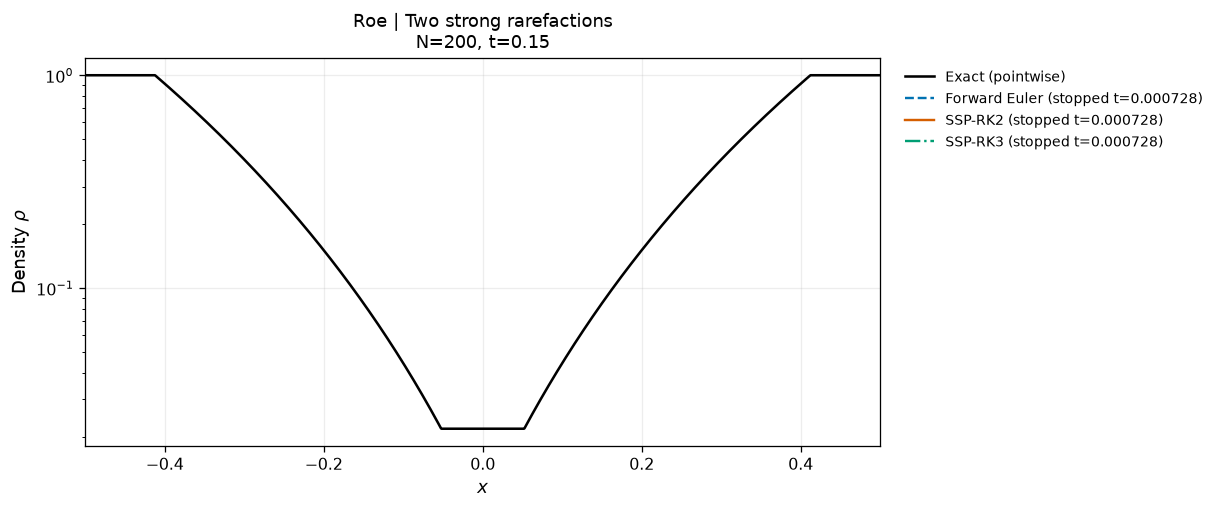

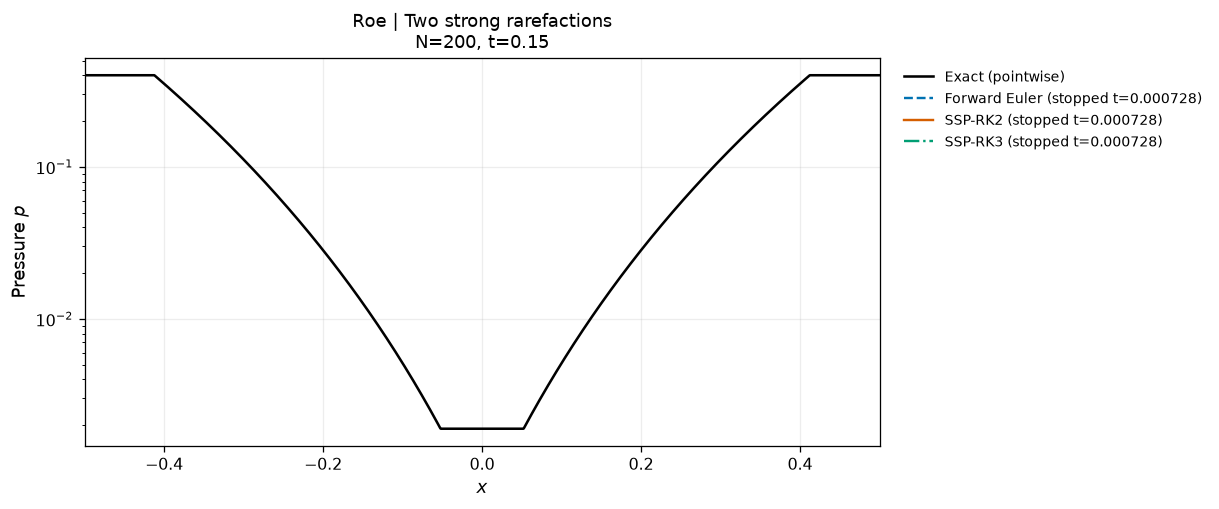

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
Roe,muscl,minmod,forward_euler,failed,0.0007277,—,0.0262,4.901e-17,2,0.001604
Roe,muscl,minmod,ssprk2,failed,0.0007277,—,0.07465,4.901e-17,3,0.001434
Roe,muscl,minmod,ssprk3,failed,0.0007277,—,0.06833,4.901e-17,4,0.001927


Roe | MUSCL (minmod) | Forward Euler: RK stage 1:  min(rho)=4.67235e-01, min(p)=-3.14328e-01
Roe | MUSCL (minmod) | SSP-RK2: RK stage 1:  min(rho)=4.86088e-01, min(p)=-2.76703e-01
Roe | MUSCL (minmod) | SSP-RK3: RK stage 1:  min(rho)=4.84912e-01, min(p)=-2.80236e-01


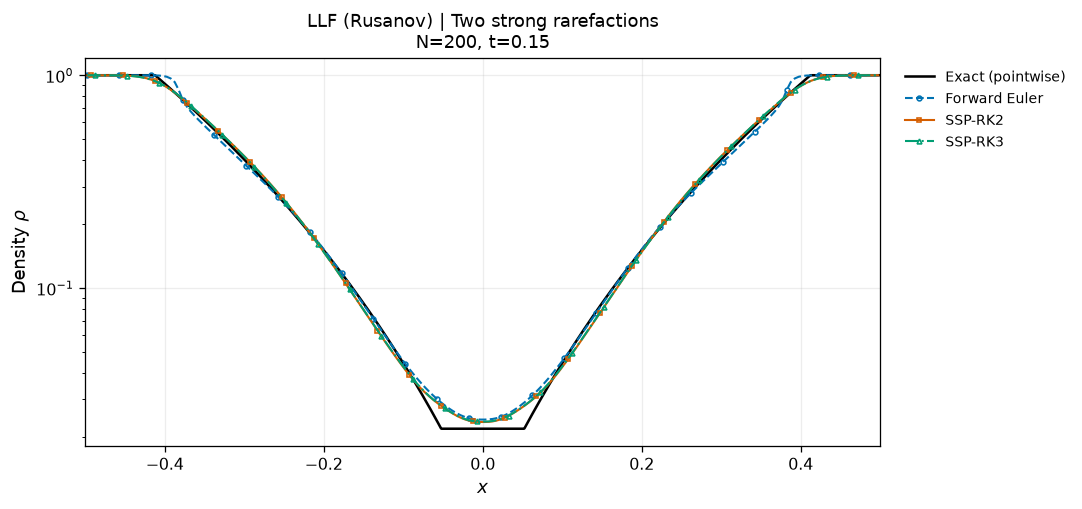

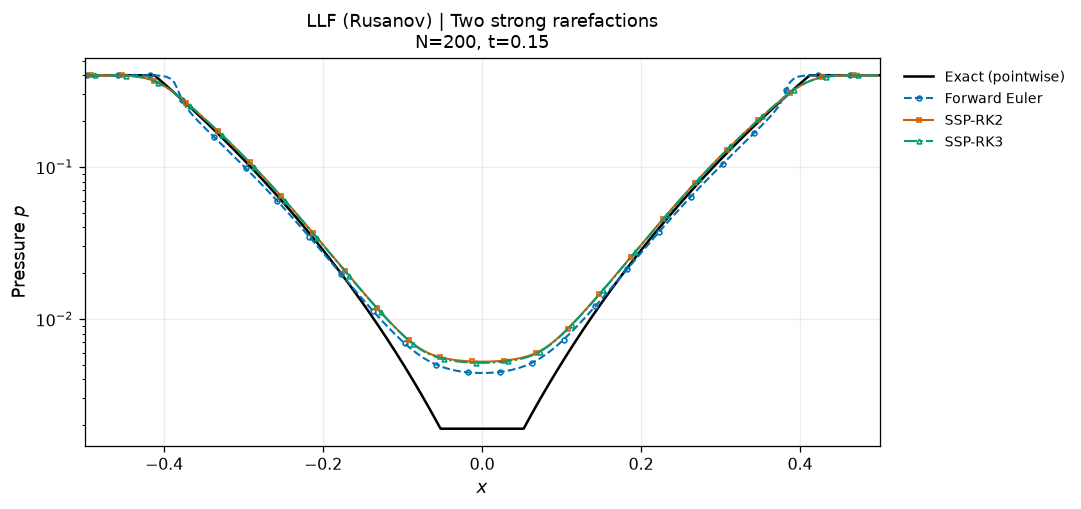

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
LLF,muscl,minmod,forward_euler,ok,0.15,0.01083,0.004405,3.553e-15,207,0.07359
LLF,muscl,minmod,ssprk2,ok,0.15,0.00803,0.00523,3.553e-15,414,0.138
LLF,muscl,minmod,ssprk3,ok,0.15,0.008045,0.005141,9.326e-15,621,0.2016


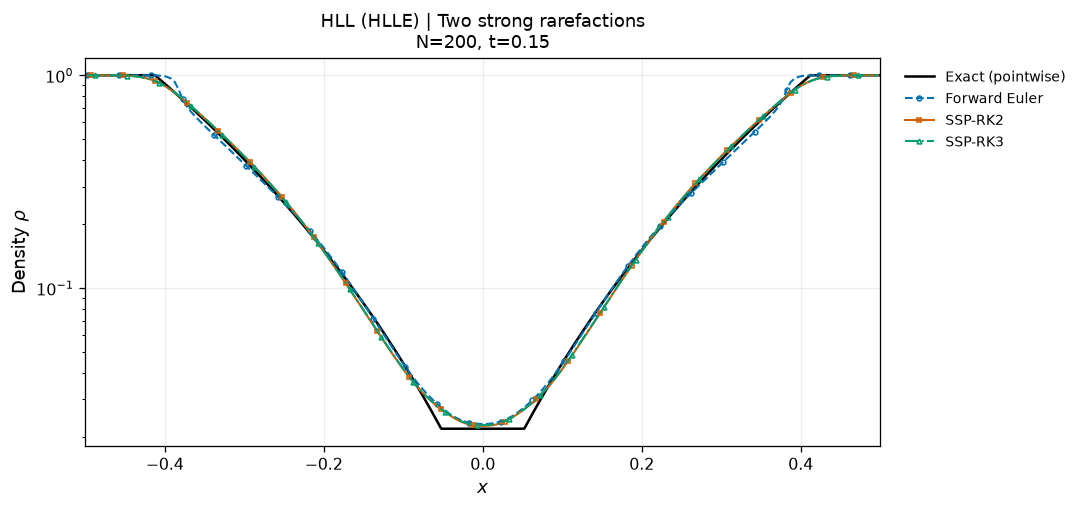

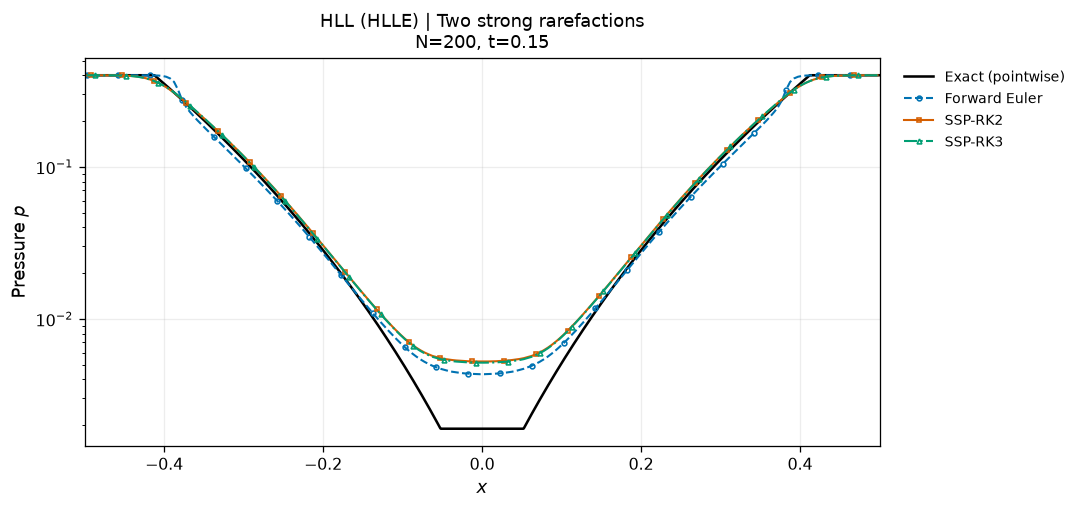

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLL,muscl,minmod,forward_euler,ok,0.15,0.01104,0.004324,3.553e-15,207,0.08629
HLL,muscl,minmod,ssprk2,ok,0.15,0.008087,0.005241,2.22e-15,414,0.1612
HLL,muscl,minmod,ssprk3,ok,0.15,0.008086,0.005149,8.882e-15,621,0.2379


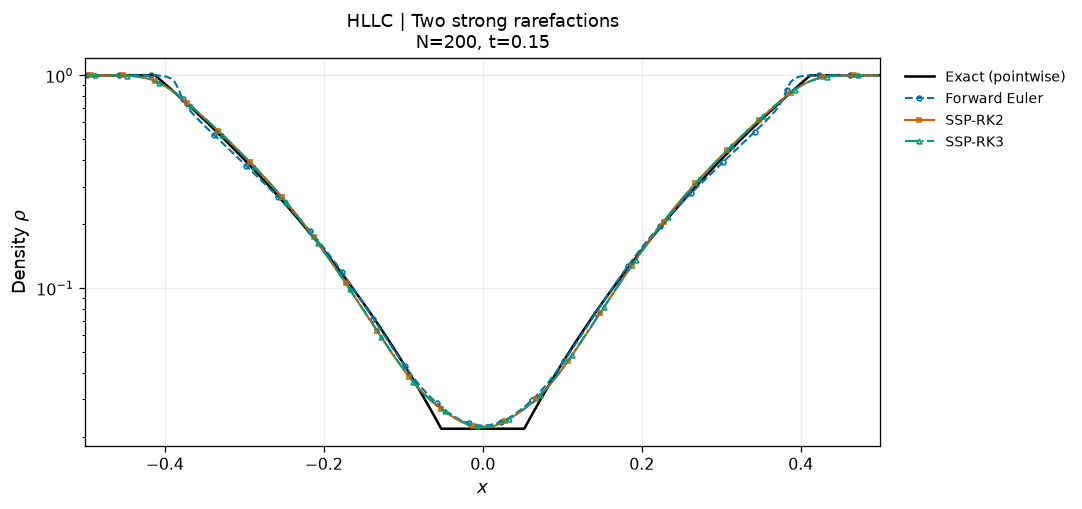

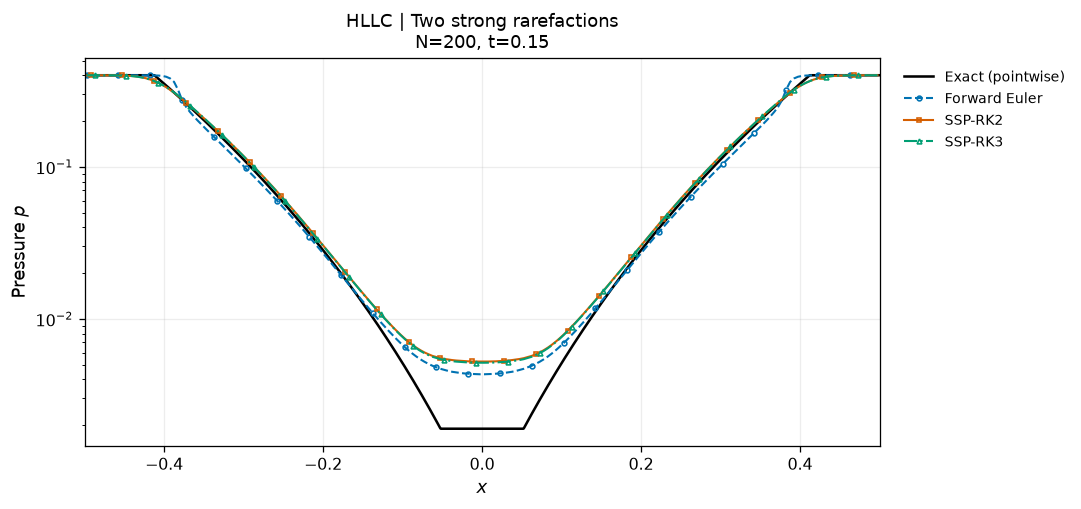

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLLC,muscl,minmod,forward_euler,ok,0.15,0.01104,0.004319,3.553e-15,207,0.1019
HLLC,muscl,minmod,ssprk2,ok,0.15,0.008081,0.005235,1.776e-15,414,0.1924
HLLC,muscl,minmod,ssprk3,ok,0.15,0.00808,0.005144,9.326e-15,621,0.2825


In [12]:
if CFG["run_robustness"]:
    for flux in CFG["fluxes"]:
        runs = ex.group_runs("double_rarefaction", flux, CFG, "time")
        ex.plot_group(runs, "time", fields=("rho", "p"))
        ex.summarize(runs)

## 9. 総合演習：数値流束・空間・時間の組合せ

まずHLLCを固定して、区分一定＋前進Euler、MUSCL＋SSP-RK2、MUSCL＋SSP-RK3を比較します。
**最初の2構成では空間と時間を同時に変えています。** これは一要素だけの比較ではなく、第III～V部で個別に学んだ要素を組み合わせた総合評価です。
次に、MUSCL＋minmod＋SSP-RK2を固定して4つの数値流束を比べます。

SSP-RK3を使っても、空間2次のMUSCLと組み合わせた全体が3次精度になるわけではありません。

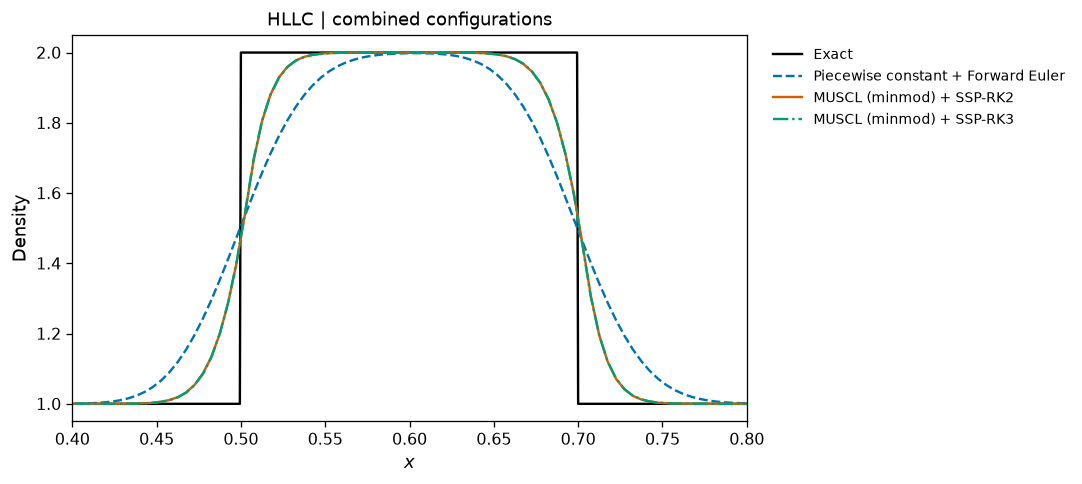

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
HLLC,constant,constant,forward_euler,ok,0.25,0.0509,1,6.661e-16,273,0.1036
HLLC,muscl,minmod,ssprk2,ok,0.25,0.0248,1,8.882e-16,546,0.2625
HLLC,muscl,minmod,ssprk3,ok,0.25,0.02475,1,1.643e-14,819,0.3889


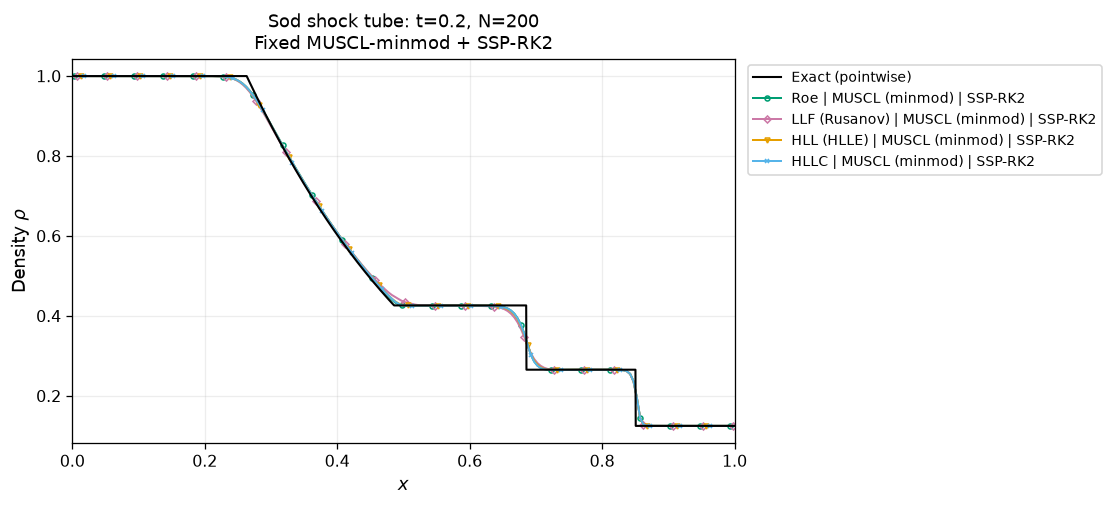

solver,reconstruction,limiter,time_integrator,status,t_reached,L1_rho,p_min,balance_max,n_rhs,seconds
Roe,muscl,minmod,ssprk2,ok,0.2,0.003984,0.1,4.441e-16,436,0.1903
LLF,muscl,minmod,ssprk2,ok,0.2,0.005112,0.1,4.441e-16,434,0.1452
HLL,muscl,minmod,ssprk2,ok,0.2,0.004209,0.1,2.22e-16,434,0.1679
HLLC,muscl,minmod,ssprk2,ok,0.2,0.004069,0.1,4.441e-16,436,0.2126


[{'problem': 'sod',
  'solver': 'Roe',
  'n': 200,
  'cfl': 0.4,
  'limiter': 'minmod',
  'wave_speeds': 'einfeldt',
  'roe_entropy': 0.1,
  'status': 'ok',
  't_reached': 0.2,
  't_target': 0.2,
  'steps': 218,
  'seconds': 0.19025855900002853,
  'rho_min': 0.125,
  'p_min': 0.1,
  'balance_max': 4.440892098500626e-16,
  'mass_balance': np.float64(3.3306690738754696e-16),
  'momentum_balance': np.float64(1.3877787807814457e-16),
  'energy_balance': np.float64(4.440892098500626e-16),
  'L1_rho': np.float64(0.0039836000094892075),
  'L1_u': np.float64(0.006762889785634652),
  'L1_p': np.float64(0.0029547528191546145),
  'amp_ratio': nan,
  'phase_rad': nan,
  'rho_overshoot': nan,
  'rho_undershoot': nan,
  'mixed_length': nan,
  'failure_trial_end': nan,
  'failure_dt': nan,
  'failure_rho_min': nan,
  'failure_p_min': nan,
  'failure_reason': '',
  'method': 'Roe | MUSCL (minmod) | SSP-RK2',
  'reconstruction': 'muscl',
  'space_order_nominal': 2,
  'time_integrator': 'ssprk2',
  'tim

In [13]:
combined = [
    ex.get_run("contact", "HLLC", CFG, reconstruction="constant", time_integrator="forward_euler"),
    ex.get_run("contact", "HLLC", CFG, reconstruction="muscl", limiter="minmod", time_integrator="ssprk2"),
    ex.get_run("contact", "HLLC", CFG, reconstruction="muscl", limiter="minmod", time_integrator="ssprk3"),
]
# 各線の空間・時間の組合せを明示するため、完全なラベルを用いる。
fig = plt.figure(figsize=(11.5, 4.8))
ax = fig.add_axes((0.08, 0.16, 0.51, 0.70))
xp = np.linspace(0.0, 1.0, 1601)
ax.plot(xp, core.exact_pointwise(core.PROBLEMS["contact"], xp, 0.25, CFG["gamma"])[:, 0], color="black", label="Exact")
for j, run in enumerate(combined):
    if run.status == "ok":
        ax.plot(run.x, run.U[:, 0], color=ex.COLORS[j], ls=ex.STYLES[j], label=mol.reconstruction_label(run.reconstruction, run.limiter) + " + " + mol.TIME_LABELS[run.time_integrator])
ax.set(xlabel="$x$", ylabel="Density", xlim=(0.4, 0.8), title="HLLC | combined configurations")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=9)
plt.show()
plt.close(fig)
ex.summarize(combined)

# 最後は空間・時間を固定し、数値流束の違いを比較する。
from euler1d_study import plot_profiles
flux_comparison = [ex.get_run("sod", flux, CFG, reconstruction="muscl", limiter="minmod", time_integrator="ssprk2") for flux in CFG["fluxes"]]
plot_profiles(flux_comparison, title_suffix="Fixed MUSCL-minmod + SSP-RK2")
ex.summarize(flux_comparison)

## 時間積分法を比較する動画

標準はHLLC・MUSCL＋minmodのSod問題です。流束や問題を設定セルで変更できます。
時間積分の刻みと動画のフレーム時刻は区別します。補間は表示専用で、計算停止後の解は外挿しません。

In [14]:
if CFG["run_movies"]:
    for flux in CFG["movie_fluxes"]:
        fig, movie = ex.comparison_movie(CFG["movie_problem"], flux, CFG, "time")
        display(HTML(movie.to_jshtml()))
        plt.close(fig)

## 発展実験と結果保存

追加実験はLax衝撃波管、Shu–Osherは2解像度の数値参照解を伴う比較です。
時間収束表・参照解の差・コスト表は、数値解とともに保存します。

**発展課題：** 空間再構築をMCや制限なしに替えて、同じ時間刻みが適切か確認してください。計算が発散した場合、時間積分の次数不足と安定性の問題を分けて説明してください。

In [15]:
if CFG["run_extras"]:
    for flux in CFG["fluxes"]:
        runs = ex.group_runs("lax", flux, CFG, "time")
        ex.plot_group(runs, "time")
        ex.summarize(runs)
if CFG["run_shu_osher"]:
    reference = shu_reference(CFG)
    for flux in CFG["fluxes"]:
        runs = ex.group_runs("shu_osher", flux, CFG, "time", n=CFG["n_shu_osher"])
        ex.plot_group(runs, "time", reference=reference)
        ex.summarize(runs, reference=reference)
if CFG["export_results"]:
    saved_rows = ex.export_results(OUTPUT_DIR, CFG, TABLES, reference=reference)

Saved 147 runs: /home/runner/work/euler1d-scheme-comparison/euler1d-scheme-comparison/five_part_outputs/temporal


## まとめ

数値流束は境界を通る流れを、空間再構築はその左右状態を、時間積分は半離散系の時間発展を決めます。
方法名だけでなく、波速推定・エントロピー補正・再構築変数・リミッター・時間積分公式・CFL規則を揃えて比較してください。

時間次数の測定には同じ空間離散化の参照解を使い、実用問題の評価には厳密解との全誤差・頑健性・計算量を併記します。衝撃波を含む問題で一つの収束次数だけを指標にしないことも重要です。
本教材は1次元・一様格子・単一理想気体の学習用実装です。包括的な正値性保証、真空、重力、冷却、MHD、多次元は対象外です。

### 三つの選択を、自分の言葉で説明する

**空間再構築**は、保存したセル平均から境界状態を作ります。**近似リーマンソルバー**は、その左右状態から境界を通る数値流束を作ります。**時間積分**は、流束差から得た変化率を使って次の状態を作ります。Godunov型は、このように局所リーマン問題を使って保存量を更新する枠組みです。

`euler1d_mol.py`では、`face_flux`が再構築と流束計算、`spatial_operator`が空間離散化した右辺、`advance_mol`が1ステップの時間更新、`simulate`が時間ループを担当します。`n_rhs`は右辺評価の計算量を把握する指標です。

**確認問題：** HLLC＋MUSCL＋SSP-RK3のうち、接触波を扱うのはどこで、セル内の傾きを作るのはどこでしょうか。

**答え：** 接触波を取り入れるのはHLLC、傾きを作るのはMUSCLです。SSP-RK3はそれらで求めた変化率を複数段階で評価して時間更新します。どれか一つの名前で、計算全体の性質が決まるわけではありません。

## 参考文献・実装の確認先

以下は原論文または開発者による公式資料です。Notebookのコードはこれらの数式・考え方を参考に、本教材用に組み立てた実装であり、Clawpack等を呼び出してはいません。

**[R1]** Clawpack, *The Euler equations of gas dynamics*：波の構造と厳密リーマン解。  
https://www.clawpack.org/riemann_book/html/Euler.html

**[R2]** Clawpack, *Approximate solvers for the Euler equations of gas dynamics*：Roe平均、HLLEの波速推定、低密度問題。  
https://www.clawpack.org/riemann_book/html/Euler_approximate.html

**[R3]** Clawpack, *Riemann Solver Package — Euler Equations*：HLLCの接触波速度と中間状態。  
https://www.clawpack.org/pyclaw/rp.html#euler-equations

**[R4]** FLASH User's Guide, *Hydrodynamics Test Problems*, §35.1.1：Sod問題と波面の位置。  
https://flash.rochester.edu/site/flashcode/user_support/flash_ug_devel/node191.html

**[R5]** Clawpack Gallery, *Shu–Osher problem*：初期状態、領域、終了時刻。  
https://www.clawpack.org/gallery/pyclaw/gallery/shocksine.html

**[R6]** Toro, E. F., Spruce, M., & Speares, W. (1994), *Restoration of the contact surface in the HLL-Riemann solver*, Shock Waves, 4, 25–34.  
https://doi.org/10.1007/BF01414629

**[R7]** Harten, A. (1983), *High resolution schemes for hyperbolic conservation laws*, Journal of Computational Physics, 49, 357–393.  
https://doi.org/10.1016/0021-9991(83)90136-5

**[R8]** Shu, C.-W., & Osher, S. (1988), *Efficient implementation of essentially non-oscillatory shock-capturing schemes*, Journal of Computational Physics, 77, 439–471.  
https://doi.org/10.1016/0021-9991(88)90177-5

**[R9]** Shu, C.-W., & Osher, S. (1989), *Efficient implementation of essentially non-oscillatory shock-capturing schemes, II*, Journal of Computational Physics, 83, 32–78.  
https://doi.org/10.1016/0021-9991(89)90222-2

初期条件・波速推定・エントロピー補正・リミッター・CFL数まで含めて、比較の設定を報告することが重要です。
「Roe」や「HLLC」という名前だけでは、実装のすべては決まりません。

**[T1]** Gkeyll developers, *Strong-Stability preserving Runge-Kutta time-steppers*：SSP-RK2・3段階SSP-RK3の更新式。
https://gkeyll.readthedocs.io/en/latest/dev/ssp-rk.html

**[T2]** Gottlieb, S., Shu, C.-W., & Tadmor, E. (2001), *Strong Stability-Preserving High-Order Time Discretization Methods*, SIAM Review, 43, 89–112.
https://doi.org/10.1137/S003614450036757X

**[TVD1]** は上の[R7]（Harten 1983）と同じ文献です。

**[TVD2]** Ketcheson, Higgs, Gottlieb, *Strong Stability Preserving Methods*. SSP法と前進Eulerの凸安定性を継承する条件。
https://www.sspsite.org/

**[TVD3]** Clawpack developers, *Pyclaw Limiters*. minmod・MCなどのリミッターの公式資料。ここではClawpackを呼び出さず、本文に記載したスカラー更新式を使います。
https://www.clawpack.org/pyclaw/evolve/limiters.html

**基礎説明の参考資料**

**[B5]** pyro developers, [Compressible hydrodynamics solvers](https://pyro2.readthedocs.io/en/latest/compressible_basics.html)：再構築と時間積分を分けたmethod-of-linesの実装例。

減衰方程式の数値は、前進EulerとSSP-RK2の公式を確認するための手計算例です。SSPの前提条件は[TVD2]、使用する更新式は本文と計算コードを参照してください。

**一次文献と標準教科書**

[P1] Godunov, S. K. (1959), *A difference method for numerical calculation of discontinuous solutions of the equations of hydrodynamics*, Mat. Sb. (N.S.), 47(89), 271–306. [Math-Netの原論文書誌](https://www.mathnet.ru/eng/sm4873)。

[P2] Roe, P. L. (1981), *Approximate Riemann solvers, parameter vectors, and difference schemes*, Journal of Computational Physics, 43, 357–372. [doi:10.1016/0021-9991(81)90128-5](https://doi.org/10.1016/0021-9991(81)90128-5)。

[P3] Harten, A., Lax, P. D., & van Leer, B. (1983), *On upstream differencing and Godunov-type schemes for hyperbolic conservation laws*, SIAM Review, 25, 35–61. [doi:10.1137/1025002](https://doi.org/10.1137/1025002)。

[P4] Einfeldt, B. (1988), *On Godunov-type methods for gas dynamics*, SIAM Journal on Numerical Analysis, 25, 294–318. [doi:10.1137/0725021](https://doi.org/10.1137/0725021)。

[P5] Einfeldt, B., Munz, C.-D., Roe, P. L., & Sjögreen, B. (1991), *On Godunov-type methods near low densities*, Journal of Computational Physics, 92, 273–295. [doi:10.1016/0021-9991(91)90211-3](https://doi.org/10.1016/0021-9991(91)90211-3)。

[P6] van Leer, B. (1979), *Towards the ultimate conservative difference scheme. V. A second-order sequel to Godunov's method*, Journal of Computational Physics, 32, 101–136. [doi:10.1016/0021-9991(79)90145-1](https://doi.org/10.1016/0021-9991(79)90145-1)。

[P7] Gottlieb, S., & Shu, C.-W. (1998), *Total variation diminishing Runge-Kutta schemes*, Mathematics of Computation, 67, 73–85. [doi:10.1090/S0025-5718-98-00913-2](https://doi.org/10.1090/S0025-5718-98-00913-2)。

[P8] LeVeque, R. J. (2002), *Finite Volume Methods for Hyperbolic Problems*, Cambridge University Press. [出版社の書誌と目次](https://www.cambridge.org/core/books/finite-volume-methods-for-hyperbolic-problems/97D5D1ACB1926DA1D4D52EAD6909E2B9)。

[P9] Toro, E. F. (2009), *Riemann Solvers and Numerical Methods for Fluid Dynamics*, 3rd ed., Springer. [doi:10.1007/b79761](https://doi.org/10.1007/b79761)。